# Intro to Machine Learning (Stanford Pre-Collegiate Summer Institutes)

**Name:** Rishi Deshpande  
**Instructor:** Dr. Jamie Fairclough  
**Date:** June 17, 2026  

---

## Project Title: Heart Disease Classification

### Dataset Information
* **Dataset Source:** [UCI Machine Learning Repository - Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease)
* **Dataset Characteristics:** Classification
* **Number of Instances:** 303  
* **Number of Features:** 13 Features (+ 1 Target Variable)
* **Target Variable:** Heart Disease (0 = No Disease, 1 = Disease Present)

### Description of Dataset
#### This project utilizes a clinical dataset that consists of 303 patient records, and has 14 diagnostic attributes. The main objective of this dataset is to determine whether or not heart disease is present within a patient based on specific diagnostics, including age and cholesterol, among others. 

In [1]:

#Installing ucimlrepo to access datasets from the UCI Machine Learning Repository
%pip install ucimlrepo

# Importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import scipy.stats as stats
from scipy.stats import skew, norm, probplot, zscore
from matplotlib.pyplot import boxplot
import warnings
warnings.filterwarnings("ignore")

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Importing Dataset by fetching directly from UCI

from ucimlrepo import fetch_ucirepo
heart_disease = fetch_ucirepo(id=45)

#Combining features and target (X and Y) into one dataframe (same structure as the sample notebook)
df = pd.concat([heart_disease.data.features, heart_disease.data.targets], axis=1)
#Converting the target variable into a binary classification problem (0 = no heart disease, 1 = heart disease)
df['num'] = df['num'].apply(lambda x: 1 if x > 0 else 0)

# Rename columns to make them presentable and understandable
rename_dict = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'Chest Pain Type',
    'trestbps': 'Resting Blood Pressure',
    'chol': 'Cholesterol',
    'fbs': 'Fasting Blood Sugar',
    'restecg': 'Resting ECG Results',
    'thalach': 'Max Heart Rate',
    'exang': 'Exercise Angina',
    'oldpeak': 'ST Depression',
    'slope': 'ST Slope',
    'ca': 'Major Vessels (Fluoroscopy)',
    'thal': 'Thalassemia Type',
    'num': 'Heart Disease Status'
}

df = df.rename(columns=rename_dict)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          303 non-null    int64  
 1   Sex                          303 non-null    int64  
 2   Chest Pain Type              303 non-null    int64  
 3   Resting Blood Pressure       303 non-null    int64  
 4   Cholesterol                  303 non-null    int64  
 5   Fasting Blood Sugar          303 non-null    int64  
 6   Resting ECG Results          303 non-null    int64  
 7   Max Heart Rate               303 non-null    int64  
 8   Exercise Angina              303 non-null    int64  
 9   ST Depression                303 non-null    float64
 10  ST Slope                     303 non-null    int64  
 11  Major Vessels (Fluoroscopy)  299 non-null    float64
 12  Thalassemia Type             301 non-null    float64
 13  Heart Disease Status

In [4]:
df.head()

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [5]:
df.tail()

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


In [6]:
df.mean()

Age                             54.438944
Sex                              0.679868
Chest Pain Type                  3.158416
Resting Blood Pressure         131.689769
Cholesterol                    246.693069
Fasting Blood Sugar              0.148515
Resting ECG Results              0.990099
Max Heart Rate                 149.607261
Exercise Angina                  0.326733
ST Depression                    1.039604
ST Slope                         1.600660
Major Vessels (Fluoroscopy)      0.672241
Thalassemia Type                 4.734219
Heart Disease Status             0.458746
dtype: float64

In [7]:
df.median()

Age                             56.0
Sex                              1.0
Chest Pain Type                  3.0
Resting Blood Pressure         130.0
Cholesterol                    241.0
Fasting Blood Sugar              0.0
Resting ECG Results              1.0
Max Heart Rate                 153.0
Exercise Angina                  0.0
ST Depression                    0.8
ST Slope                         2.0
Major Vessels (Fluoroscopy)      0.0
Thalassemia Type                 3.0
Heart Disease Status             0.0
dtype: float64

In [8]:
df.mode()

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
0,58.0,1.0,4.0,120.0,197,0.0,0.0,162.0,0.0,0.0,1.0,0.0,3.0,0.0
1,NaN,NaN,NaN,NaN,204,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.std()

Age                             9.038662
Sex                             0.467299
Chest Pain Type                 0.960126
Resting Blood Pressure         17.599748
Cholesterol                    51.776918
Fasting Blood Sugar             0.356198
Resting ECG Results             0.994971
Max Heart Rate                 22.875003
Exercise Angina                 0.469794
ST Depression                   1.161075
ST Slope                        0.616226
Major Vessels (Fluoroscopy)     0.937438
Thalassemia Type                1.939706
Heart Disease Status            0.499120
dtype: float64

In [10]:
df.std()*2

Age                             18.077325
Sex                              0.934598
Chest Pain Type                  1.920251
Resting Blood Pressure          35.199495
Cholesterol                    103.553835
Fasting Blood Sugar              0.712396
Resting ECG Results              1.989943
Max Heart Rate                  45.750007
Exercise Angina                  0.939589
ST Depression                    2.322150
ST Slope                         1.232452
Major Vessels (Fluoroscopy)      1.874877
Thalassemia Type                 3.879412
Heart Disease Status             0.998239
dtype: float64

In [11]:
df.columns

Index(['Age', 'Sex', 'Chest Pain Type', 'Resting Blood Pressure',
       'Cholesterol', 'Fasting Blood Sugar', 'Resting ECG Results',
       'Max Heart Rate', 'Exercise Angina', 'ST Depression', 'ST Slope',
       'Major Vessels (Fluoroscopy)', 'Thalassemia Type',
       'Heart Disease Status'],
      dtype='object')

In [12]:
df.shape

(303, 14)

In [13]:
df.describe()

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


In [14]:
#easier to read the chart
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
Sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
Chest Pain Type,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
Resting Blood Pressure,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
Cholesterol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
Fasting Blood Sugar,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
Resting ECG Results,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
Max Heart Rate,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
Exercise Angina,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
ST Depression,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [15]:
# Reduce number of decimals
pd.set_option('display.float_format', lambda x: '%.3f' % x)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,303.000,54.439,9.039,29.000,48.000,56.000,61.000,77.000
Sex,303.000,0.680,0.467,0.000,0.000,1.000,1.000,1.000
Chest Pain Type,303.000,3.158,0.960,1.000,3.000,3.000,4.000,4.000
Resting Blood Pressure,303.000,131.690,17.600,94.000,120.000,130.000,140.000,200.000
Cholesterol,303.000,246.693,51.777,126.000,211.000,241.000,275.000,564.000
Fasting Blood Sugar,303.000,0.149,0.356,0.000,0.000,0.000,0.000,1.000
Resting ECG Results,303.000,0.990,0.995,0.000,0.000,1.000,2.000,2.000
Max Heart Rate,303.000,149.607,22.875,71.000,133.500,153.000,166.000,202.000
Exercise Angina,303.000,0.327,0.470,0.000,0.000,0.000,1.000,1.000
ST Depression,303.000,1.040,1.161,0.000,0.000,0.800,1.600,6.200


In [16]:
df['Heart Disease Status'].value_counts()

Heart Disease Status
0    164
1    139
Name: count, dtype: int64

In [17]:
df["Heart Disease Status"].value_counts()

Heart Disease Status
0    164
1    139
Name: count, dtype: int64

In [18]:
df['Cholesterol'].value_counts()

Cholesterol
204    6
197    6
234    6
269    5
212    5
      ..
340    1
160    1
394    1
184    1
131    1
Name: count, Length: 152, dtype: int64

In [19]:
np.random.seed()
df.sample(n=10)

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
55,54,1,4,124,266,0,2,109,1,2.200,2,1.000,7.000,1
118,63,1,4,130,330,1,2,132,1,1.800,1,3.000,7.000,1
207,50,1,4,144,200,0,2,126,1,0.900,2,0.000,7.000,1
102,57,0,4,128,303,0,2,159,0,0.000,1,1.000,3.000,0
252,64,1,4,128,263,0,0,105,1,0.200,2,1.000,7.000,0
33,59,1,4,135,234,0,0,161,0,0.500,2,0.000,7.000,0
246,58,1,4,100,234,0,0,156,0,0.100,1,1.000,7.000,1
181,56,0,4,134,409,0,2,150,1,1.900,2,2.000,7.000,1
16,48,1,2,110,229,0,0,168,0,1.000,3,0.000,7.000,1
138,35,1,4,120,198,0,0,130,1,1.600,2,0.000,7.000,1


In [20]:
df[df.duplicated()].count()

Age                            0
Sex                            0
Chest Pain Type                0
Resting Blood Pressure         0
Cholesterol                    0
Fasting Blood Sugar            0
Resting ECG Results            0
Max Heart Rate                 0
Exercise Angina                0
ST Depression                  0
ST Slope                       0
Major Vessels (Fluoroscopy)    0
Thalassemia Type               0
Heart Disease Status           0
dtype: int64

In [21]:
NaN = np.nan
df["New_Column"] = NaN

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          303 non-null    int64  
 1   Sex                          303 non-null    int64  
 2   Chest Pain Type              303 non-null    int64  
 3   Resting Blood Pressure       303 non-null    int64  
 4   Cholesterol                  303 non-null    int64  
 5   Fasting Blood Sugar          303 non-null    int64  
 6   Resting ECG Results          303 non-null    int64  
 7   Max Heart Rate               303 non-null    int64  
 8   Exercise Angina              303 non-null    int64  
 9   ST Depression                303 non-null    float64
 10  ST Slope                     303 non-null    int64  
 11  Major Vessels (Fluoroscopy)  299 non-null    float64
 12  Thalassemia Type             301 non-null    float64
 13  Heart Disease Status

So Far, dataset has very little missing values, no duplicates, and all columns are int64 or float64, while some need to be made categorical such as sex, num and thal.

In [23]:
del df['New_Column']

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          303 non-null    int64  
 1   Sex                          303 non-null    int64  
 2   Chest Pain Type              303 non-null    int64  
 3   Resting Blood Pressure       303 non-null    int64  
 4   Cholesterol                  303 non-null    int64  
 5   Fasting Blood Sugar          303 non-null    int64  
 6   Resting ECG Results          303 non-null    int64  
 7   Max Heart Rate               303 non-null    int64  
 8   Exercise Angina              303 non-null    int64  
 9   ST Depression                303 non-null    float64
 10  ST Slope                     303 non-null    int64  
 11  Major Vessels (Fluoroscopy)  299 non-null    float64
 12  Thalassemia Type             301 non-null    float64
 13  Heart Disease Status

In [25]:
df.min()

Age                            29.000
Sex                             0.000
Chest Pain Type                 1.000
Resting Blood Pressure         94.000
Cholesterol                   126.000
Fasting Blood Sugar             0.000
Resting ECG Results             0.000
Max Heart Rate                 71.000
Exercise Angina                 0.000
ST Depression                   0.000
ST Slope                        1.000
Major Vessels (Fluoroscopy)     0.000
Thalassemia Type                3.000
Heart Disease Status            0.000
dtype: float64

In [26]:
df.max()

Age                            77.000
Sex                             1.000
Chest Pain Type                 4.000
Resting Blood Pressure        200.000
Cholesterol                   564.000
Fasting Blood Sugar             1.000
Resting ECG Results             2.000
Max Heart Rate                202.000
Exercise Angina                 1.000
ST Depression                   6.200
ST Slope                        3.000
Major Vessels (Fluoroscopy)     3.000
Thalassemia Type                7.000
Heart Disease Status            1.000
dtype: float64

In [27]:
# Flag suspiciously low values
for col in df.select_dtypes(include=[np.number]).columns:
    min_val = df[col].min()
    if min_val < 0:
        print(f"Warning: {col} has a negative value: {min_val}")
    elif min_val == 0:
        print(f"Note: {col} has a zero value: {min_val}")

Note: Sex has a zero value: 0
Note: Fasting Blood Sugar has a zero value: 0
Note: Resting ECG Results has a zero value: 0
Note: Exercise Angina has a zero value: 0
Note: ST Depression has a zero value: 0.0
Note: Major Vessels (Fluoroscopy) has a zero value: 0.0
Note: Heart Disease Status has a zero value: 0


In [28]:
# Function to return suspiciously high values for each variable
def get_high_outliers(df, n_std=3):
    high_outliers = {}
    numeric_cols = df.select_dtypes(include=[np.number])

    for col in numeric_cols.columns:
        mean_val = numeric_cols[col].mean()
        std_val = numeric_cols[col].std()
        upper_bound = mean_val + n_std * std_val
        outlier_vals = df[df[col] > upper_bound][col]

        if not outlier_vals.empty:
            high_outliers[col] = outlier_vals

    return high_outliers

# Get high outliers using 3×std
high_outlier_dict = get_high_outliers(df, n_std=3)

# View results
for col, vals in high_outlier_dict.items():
    print(f"\n {col} values > mean + 3×std:")
    print(vals.to_string(index=False))


 Resting Blood Pressure values > mean + 3×std:
200
192

 Cholesterol values > mean + 3×std:
417
407
564
409

 ST Depression values > mean + 3×std:
6.200
5.600


## Zero Values:
All zero values are either categorical values or valid zeros (Possible in a real-world patient)

## Outliers: 
Small number of extreme outliers in blood pressure, cholesterol and ST depression, but these values are possible, just very severe.

In [29]:
# Select only numeric features
numeric_variables = df.select_dtypes(include=[np.number])

# Calculate skewness for each numeric feature
skewness = numeric_variables.apply(lambda x: skew(x.dropna()))
skewed_variables = skewness[abs(skewness) > 0.75]

# Display results
print("Skewed Variables (|skew| > 0.75):")
print(skewed_variables)

Skewed Variables (|skew| > 0.75):
Sex                           -0.771
Chest Pain Type               -0.838
Cholesterol                    1.130
Fasting Blood Sugar            1.977
ST Depression                  1.263
Major Vessels (Fluoroscopy)    1.183
dtype: float64


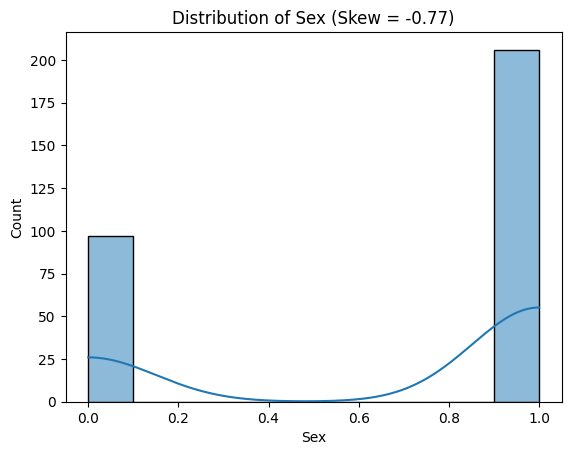

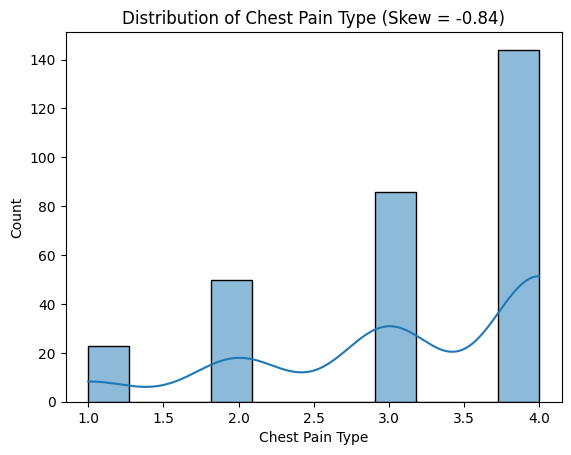

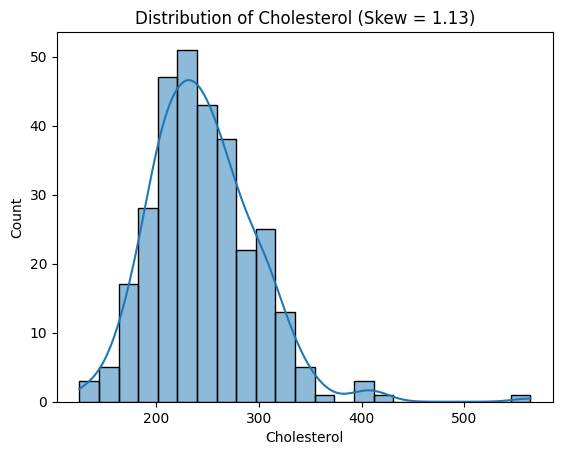

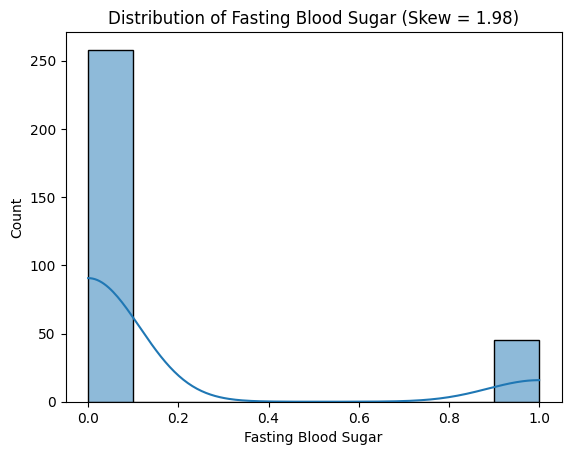

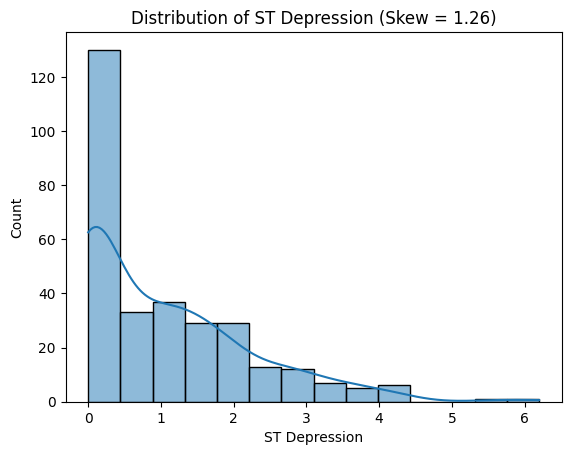

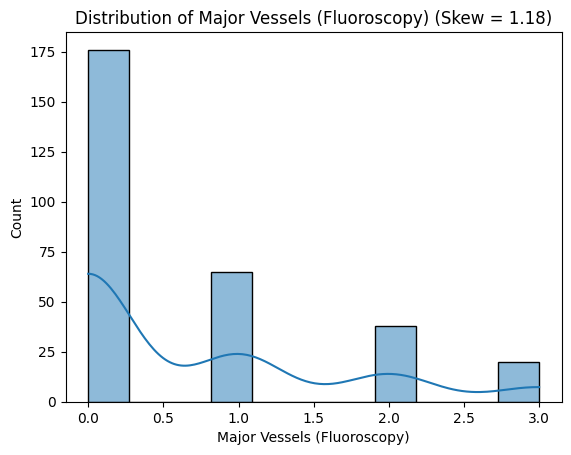

In [30]:
# Visualize skewed variables

for feature in skewed_variables.index:
    plt.figure()
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature} (Skew = {skewness[feature]:.2f})')
    plt.show();

### Continuous Features (ST Depression, Cholesterol, Major Vessels)
* Heavily right skewed
* A majority of the patients sit at normal baseline levels, while a small group of high-risk outliers help create the tail on the right side of the graph

### Categorical Features (Sex, Chest Pain, Fasting Blood Sugar)
* These graphs show imbalances rather than skewness, as they are categories and not continuous measurements.
* The dataset is weighed toward male patients, individduals with fasting blood sugar under 120 mg/dl, and patients experiencing Type 4 chest pain

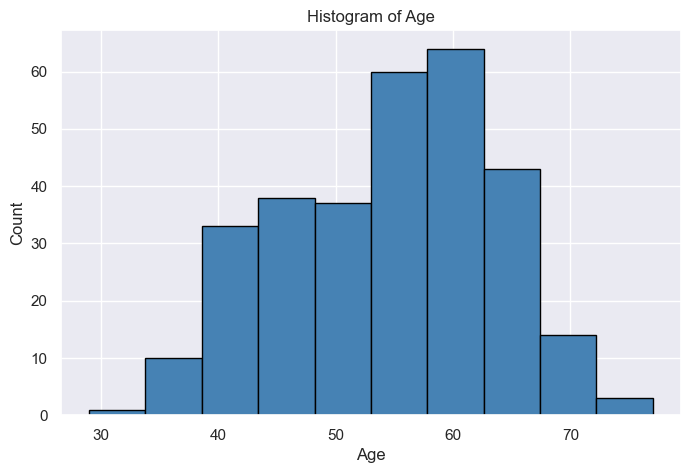

In [31]:
# Including histogram and other visualizations

sns.set_theme(style = "darkgrid")

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Age"], color="steelblue", edgecolor="black", bins=10)
plt.xlabel ("Age")
plt.ylabel("Count")
plt.title("Histogram of Age")
plt.show()

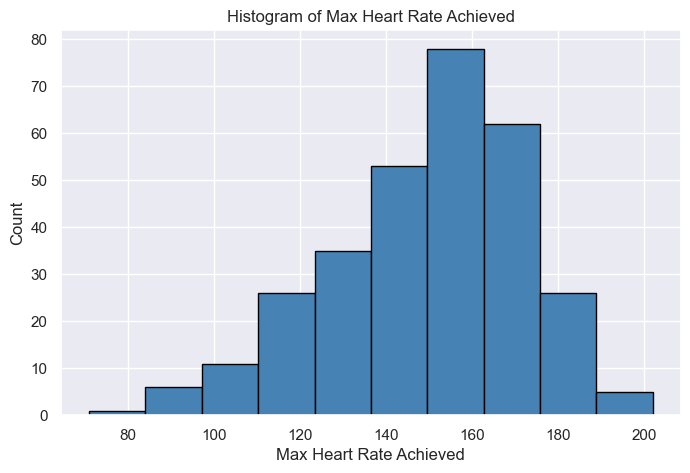

In [32]:
# Include histogram and other visualizations

sns.set_theme(style = "darkgrid")

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Max Heart Rate"], color="steelblue", edgecolor="black", bins=10)
plt.xlabel ("Max Heart Rate Achieved")
plt.ylabel("Count")
plt.title("Histogram of Max Heart Rate Achieved")
plt.show()

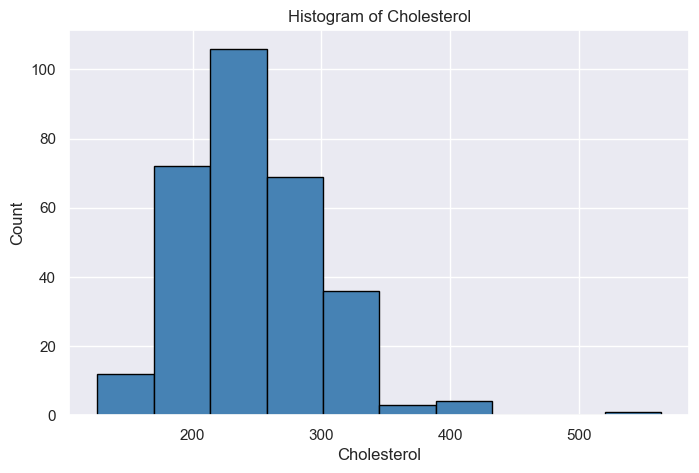

In [33]:
# Include histogram and other visualizations

sns.set_theme(style = "darkgrid")

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Cholesterol"], color="steelblue", edgecolor="black", bins=10)
plt.xlabel ("Cholesterol")
plt.ylabel("Count")
plt.title("Histogram of Cholesterol")
plt.show()

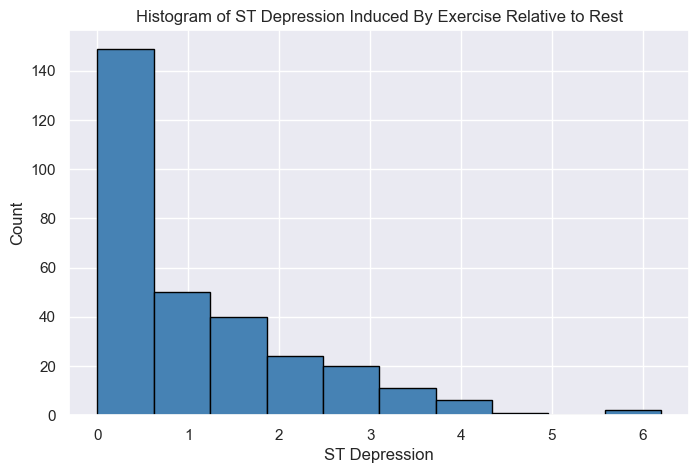

In [34]:
# Include histogram and other visualizations

sns.set_theme(style = "darkgrid")

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["ST Depression"], color="steelblue", edgecolor="black", bins=10)
plt.xlabel ("ST Depression")
plt.ylabel("Count")
plt.title("Histogram of ST Depression Induced By Exercise Relative to Rest")
#ST Means an interval on an electrocardiogram 
plt.show()

### **ST Depression indicates oxygen deprivation in the heart muscle under stress**

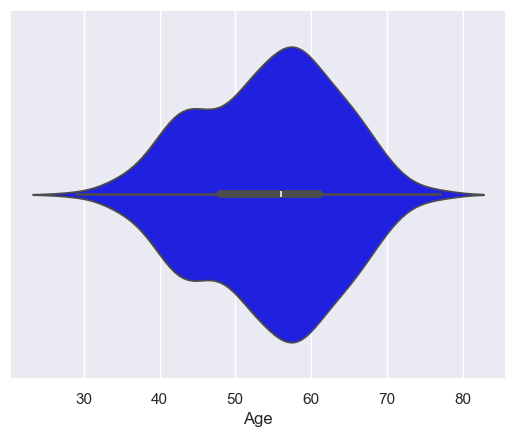

In [35]:
sns.set_theme(style="darkgrid")

sns.violinplot(x=df["Age"], color = "blue")
plt.show()

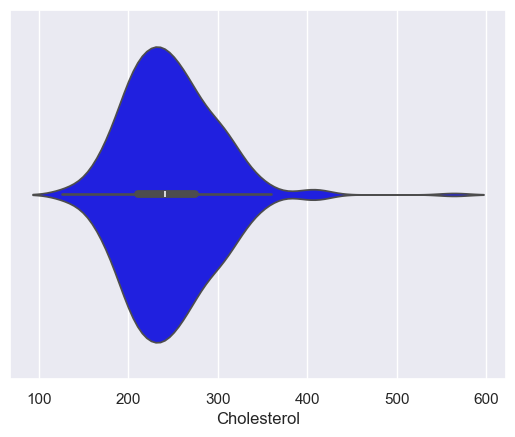

In [36]:
sns.set_theme(style="darkgrid")

sns.violinplot(x=df["Cholesterol"], color = "blue")
plt.show()

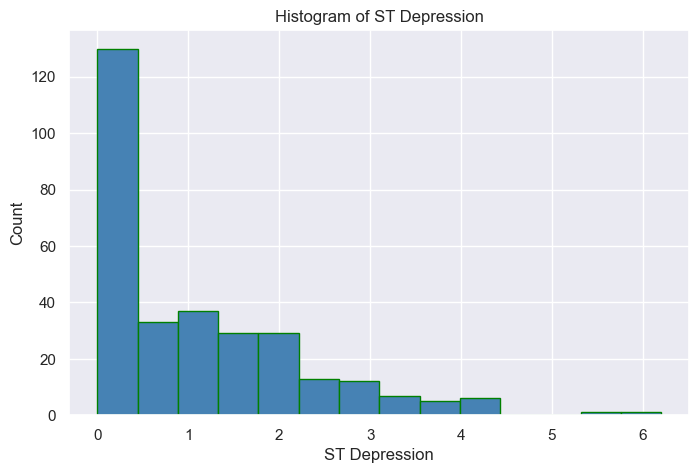

In [37]:
# Apply Seaborn styling (gridlines, fonts, spacing)
sns.set_theme(style="darkgrid")  # or "whitegrid", "ticks", etc.

# Plot
plt.figure(figsize=(8, 5))
plt.hist(df["ST Depression"], 
         color='steelblue', # Change this to your favorite color
         edgecolor='green', 
         bins=14) # Change the bin count to your age
plt.xlabel("ST Depression")
plt.ylabel("Count")
plt.title("Histogram of ST Depression")
plt.show()

## Exploratory Data Analysis

In [38]:
#Pearson's Correlation
df.corr()

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
Age,1.000,-0.098,0.104,0.285,0.209,0.119,0.149,-0.394,0.092,0.204,0.162,0.363,0.127,0.223
Sex,-0.098,1.000,0.010,-0.064,-0.200,0.048,0.022,-0.049,0.146,0.102,0.038,0.093,0.381,0.277
Chest Pain Type,0.104,0.010,1.000,-0.036,0.072,-0.040,0.068,-0.334,0.384,0.202,0.152,0.233,0.265,0.414
Resting Blood Pressure,0.285,-0.064,-0.036,1.000,0.130,0.175,0.147,-0.045,0.065,0.189,0.117,0.099,0.134,0.151
Cholesterol,0.209,-0.200,0.072,0.130,1.000,0.010,0.171,-0.003,0.061,0.047,-0.004,0.119,0.014,0.085
Fasting Blood Sugar,0.119,0.048,-0.040,0.175,0.010,1.000,0.070,-0.008,0.026,0.006,0.060,0.145,0.071,0.025
Resting ECG Results,0.149,0.022,0.068,0.147,0.171,0.070,1.000,-0.083,0.085,0.114,0.134,0.128,0.025,0.169
Max Heart Rate,-0.394,-0.049,-0.334,-0.045,-0.003,-0.008,-0.083,1.000,-0.378,-0.343,-0.386,-0.264,-0.280,-0.417
Exercise Angina,0.092,0.146,0.384,0.065,0.061,0.026,0.085,-0.378,1.000,0.288,0.258,0.146,0.330,0.432
ST Depression,0.204,0.102,0.202,0.189,0.047,0.006,0.114,-0.343,0.288,1.000,0.578,0.296,0.341,0.425


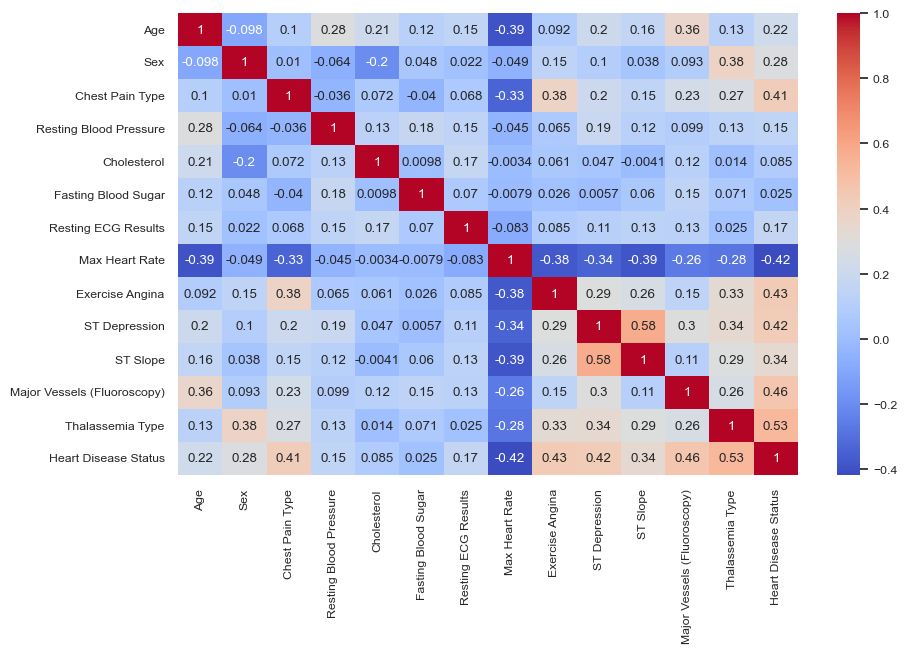

In [39]:
# Pearson's correlation (with heatmap and coolwarm color)
plt.figure(figsize=(10,6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5
sns.heatmap(df.corr(), annot=True, cmap="coolwarm");
plt.show()

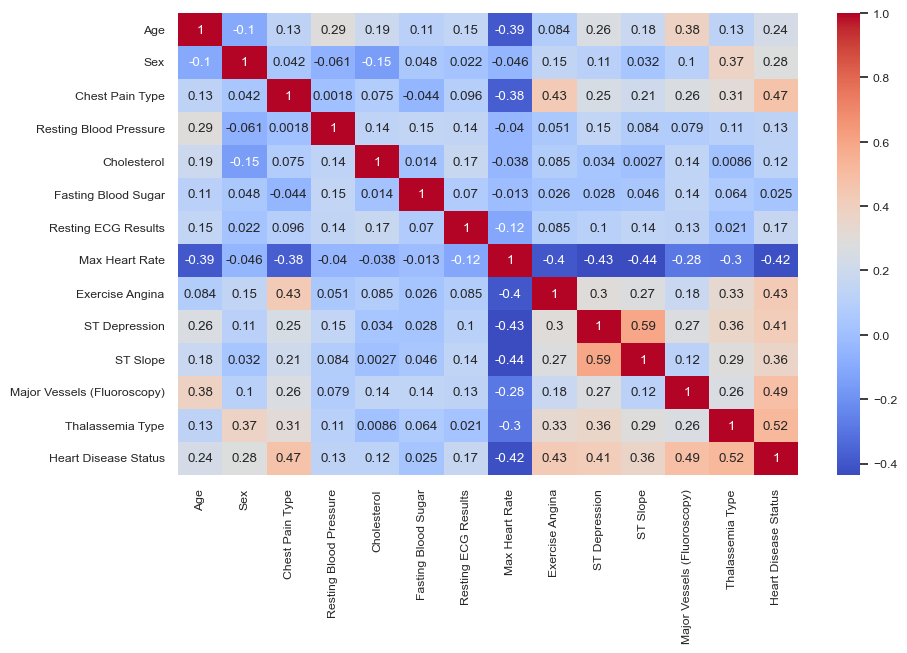

In [40]:
# Spearman's Rank or Spearman's Rho correlation
plt.figure(figsize=(10,6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5
sns.heatmap(df.corr(method='spearman'), annot=True, cmap="coolwarm"); # nonparametric correlation
plt.show()

In [41]:
#Phi K correlation

%pip install phik
import phik
from phik import resources, report

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [42]:
df.phik_matrix()

interval columns not set, guessing: ['Age', 'Sex', 'Chest Pain Type', 'Resting Blood Pressure', 'Cholesterol', 'Fasting Blood Sugar', 'Resting ECG Results', 'Max Heart Rate', 'Exercise Angina', 'ST Depression', 'ST Slope', 'Major Vessels (Fluoroscopy)', 'Thalassemia Type', 'Heart Disease Status']


,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Max Heart Rate,Exercise Angina,ST Depression,ST Slope,Major Vessels (Fluoroscopy),Thalassemia Type,Heart Disease Status
Age,1.000,0.000,0.176,0.223,0.000,0.000,0.340,0.530,0.091,0.000,0.091,0.350,0.134,0.329
Sex,0.000,1.000,0.170,0.000,0.287,0.000,0.044,0.230,0.197,0.000,0.000,0.144,0.234,0.403
Chest Pain Type,0.176,0.170,1.000,0.197,0.000,0.090,0.083,0.344,0.655,0.265,0.196,0.380,0.249,0.718
Resting Blood Pressure,0.223,0.000,0.197,1.000,0.000,0.158,0.287,0.212,0.133,0.224,0.000,0.084,0.090,0.000
Cholesterol,0.000,0.287,0.000,0.000,1.000,0.000,0.212,0.000,0.000,0.099,0.000,0.088,0.000,0.077
Fasting Blood Sugar,0.000,0.000,0.090,0.158,0.000,1.000,0.015,0.000,0.000,0.000,0.041,0.183,0.044,0.000
Resting ECG Results,0.340,0.044,0.083,0.287,0.212,0.015,1.000,0.134,0.030,0.647,0.305,0.061,0.000,0.099
Max Heart Rate,0.530,0.230,0.344,0.212,0.000,0.000,0.134,1.000,0.501,0.301,0.451,0.279,0.354,0.529
Exercise Angina,0.091,0.197,0.655,0.133,0.000,0.000,0.030,0.501,1.000,0.285,0.168,0.271,0.195,0.615
ST Depression,0.000,0.000,0.265,0.224,0.099,0.000,0.647,0.301,0.285,1.000,0.736,0.347,0.562,0.431


In [43]:
from phik.report import plot_correlation_matrix
phik_overview = df.phik_matrix()

interval columns not set, guessing: ['Age', 'Sex', 'Chest Pain Type', 'Resting Blood Pressure', 'Cholesterol', 'Fasting Blood Sugar', 'Resting ECG Results', 'Max Heart Rate', 'Exercise Angina', 'ST Depression', 'ST Slope', 'Major Vessels (Fluoroscopy)', 'Thalassemia Type', 'Heart Disease Status']


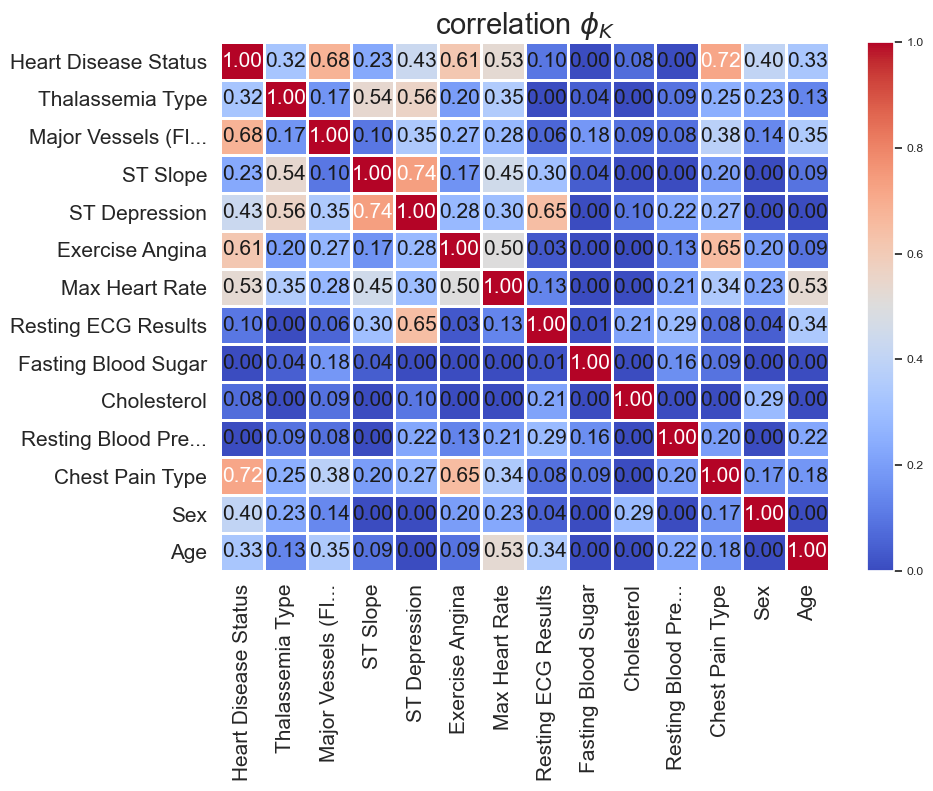

In [44]:
# Phi K heatmap (credit: Jai Gupta, Stanford SPCS 2023)
plot_correlation_matrix(phik_overview.values, 
                        x_labels=phik_overview.columns, 
                        y_labels=phik_overview.index, 
                        vmin=0, vmax=1, color_map="coolwarm", 
                        title=r"correlation $\phi_K$", 
                        fontsize_factor=1.5, 
                        figsize=(10, 8))
plt.tight_layout()
plt.show()


**Strongest Predictors**: Across the three matrices (**Pearson, Spearman, and PhiK**), the features **Major Vessels (Flouroscopy), Thalassemia Type, and Chest Pain Type** show the strongest correlation with num.

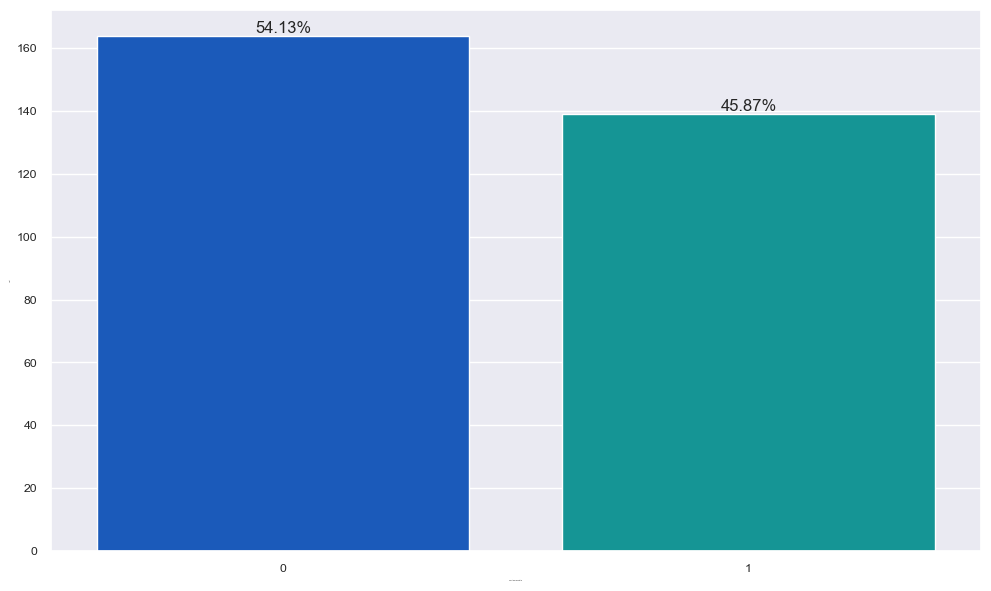

In [45]:
# Function to create plot for categorical variable

# Annotate barplot
def annotate_bars(ax, feature):
    total = len(feature)
    for p in ax.patches:
        percentage = '{:.2f}%'.format(100 * p.get_height() / total)
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(percentage, (x, y), ha='center', va='bottom', size=12)

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='Heart Disease Status', palette='winter', ax=ax)
annotate_bars(ax, df['Heart Disease Status'])
plt.tight_layout()
plt.show()


In [46]:
# From UT Austin Computer Science Department
# Use this function to create a combo boxplot and histogram for continuous (I/R --> int64 and float64) variables

def boxplot_histogram (feature, figsize=(10,7), bins = None):
    sns.set(font_scale=2) 
    f2, (ax_box2, ax_hist2) = plt.subplots(nrows = 2, 
                                           sharex = True,
                                           gridspec_kw = {"height_ratios": (.25, .75)}, 
                                           figsize = figsize 
                                           ) 
    sns.boxplot(feature, ax=ax_box2, orient = "h", showmeans=True, color='red') # mean value will be noted
    sns.distplot(feature, kde=F, ax=ax_hist2, bins=bins) if bins else sns.distplot(feature, kde=False, ax=ax_hist2, fit=norm)
    ax_hist2.axvline(np.mean(feature), color='g', linestyle='--') # Add mean to the histogram
    ax_hist2.axvline(np.median(feature), color='black', linestyle='-') # Add median to the histogram
    plt.axvline(feature.mode()[0], color='r', linestyle='dashed', linewidth=1); #Add mode to the histogram


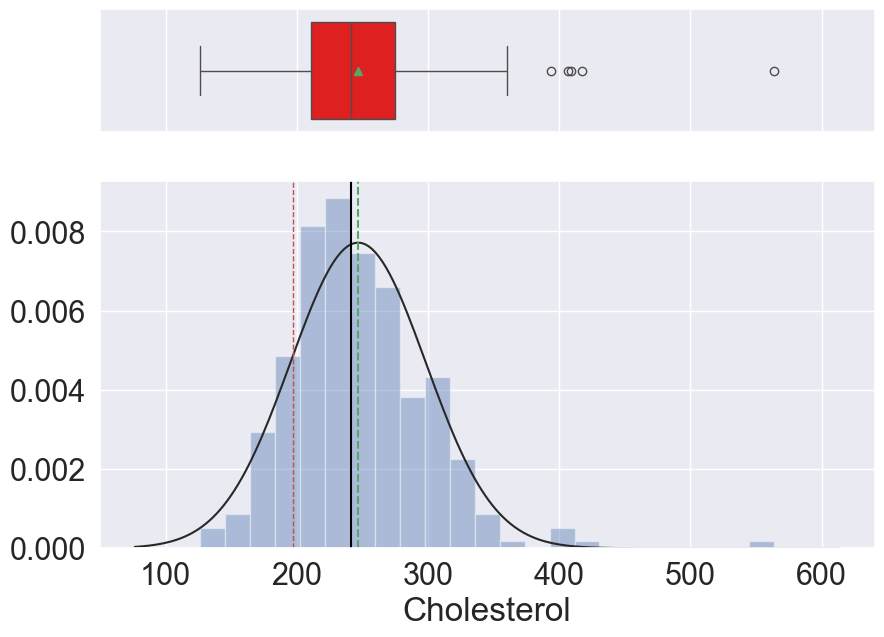

In [47]:
boxplot_histogram(df.Cholesterol)
plt.show()

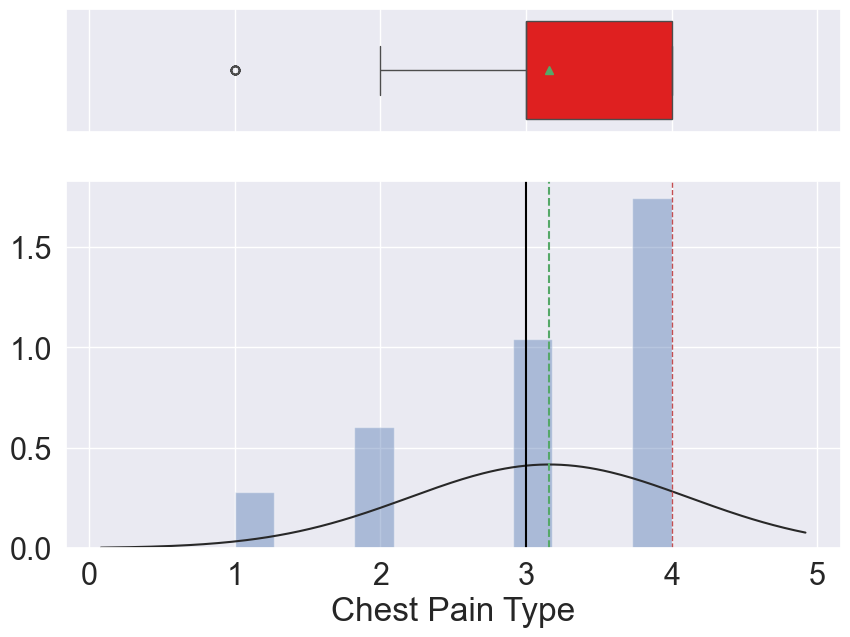

In [48]:
boxplot_histogram(df['Chest Pain Type'])
plt.show()

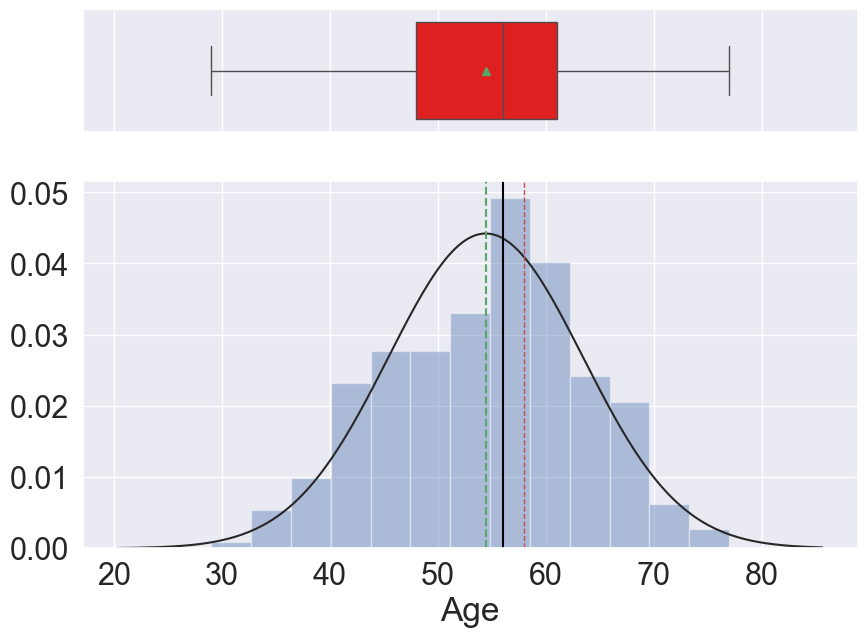

In [49]:
boxplot_histogram(df.Age)
plt.show()

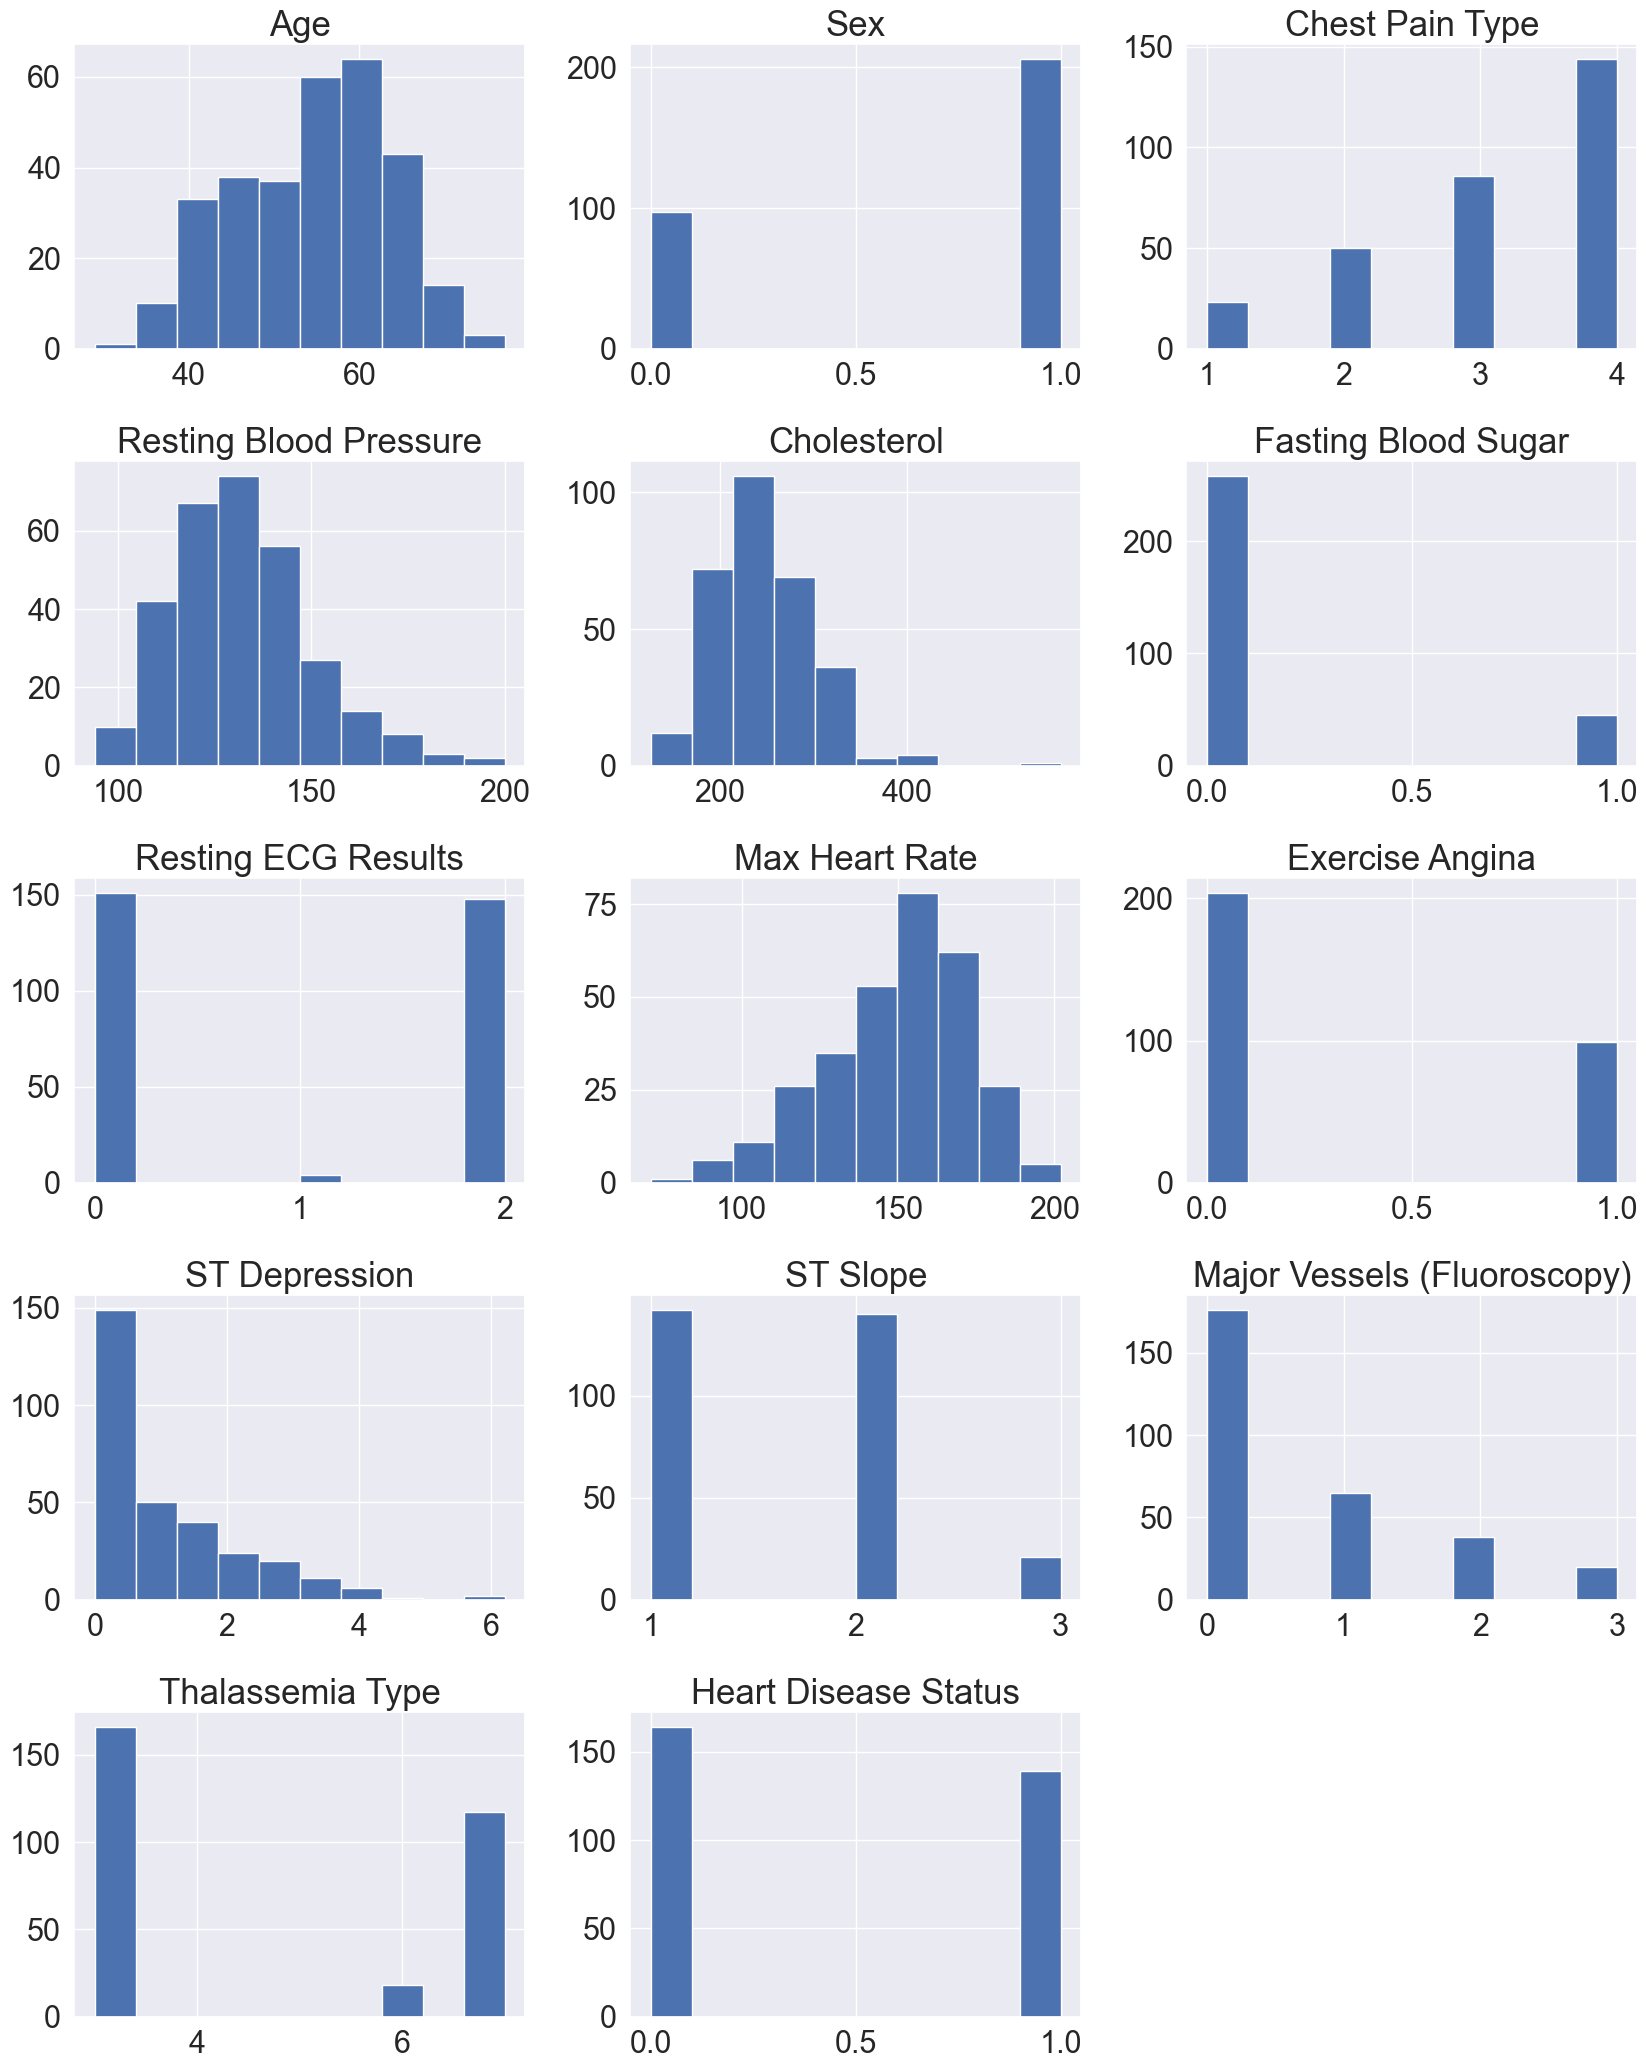

In [50]:
# Plot histograms to check the distribution of each numeric variable
from scipy.stats import norm
all_col = df.select_dtypes(include=np.number).columns.tolist()
plt.figure(figsize=(17,75))

for i in range(len(all_col)):
    plt.subplot(18,3,i+1)
    plt.hist(df[all_col[i]])
    plt.tight_layout()
    plt.title(all_col[i],fontsize=25)
    
plt.show()

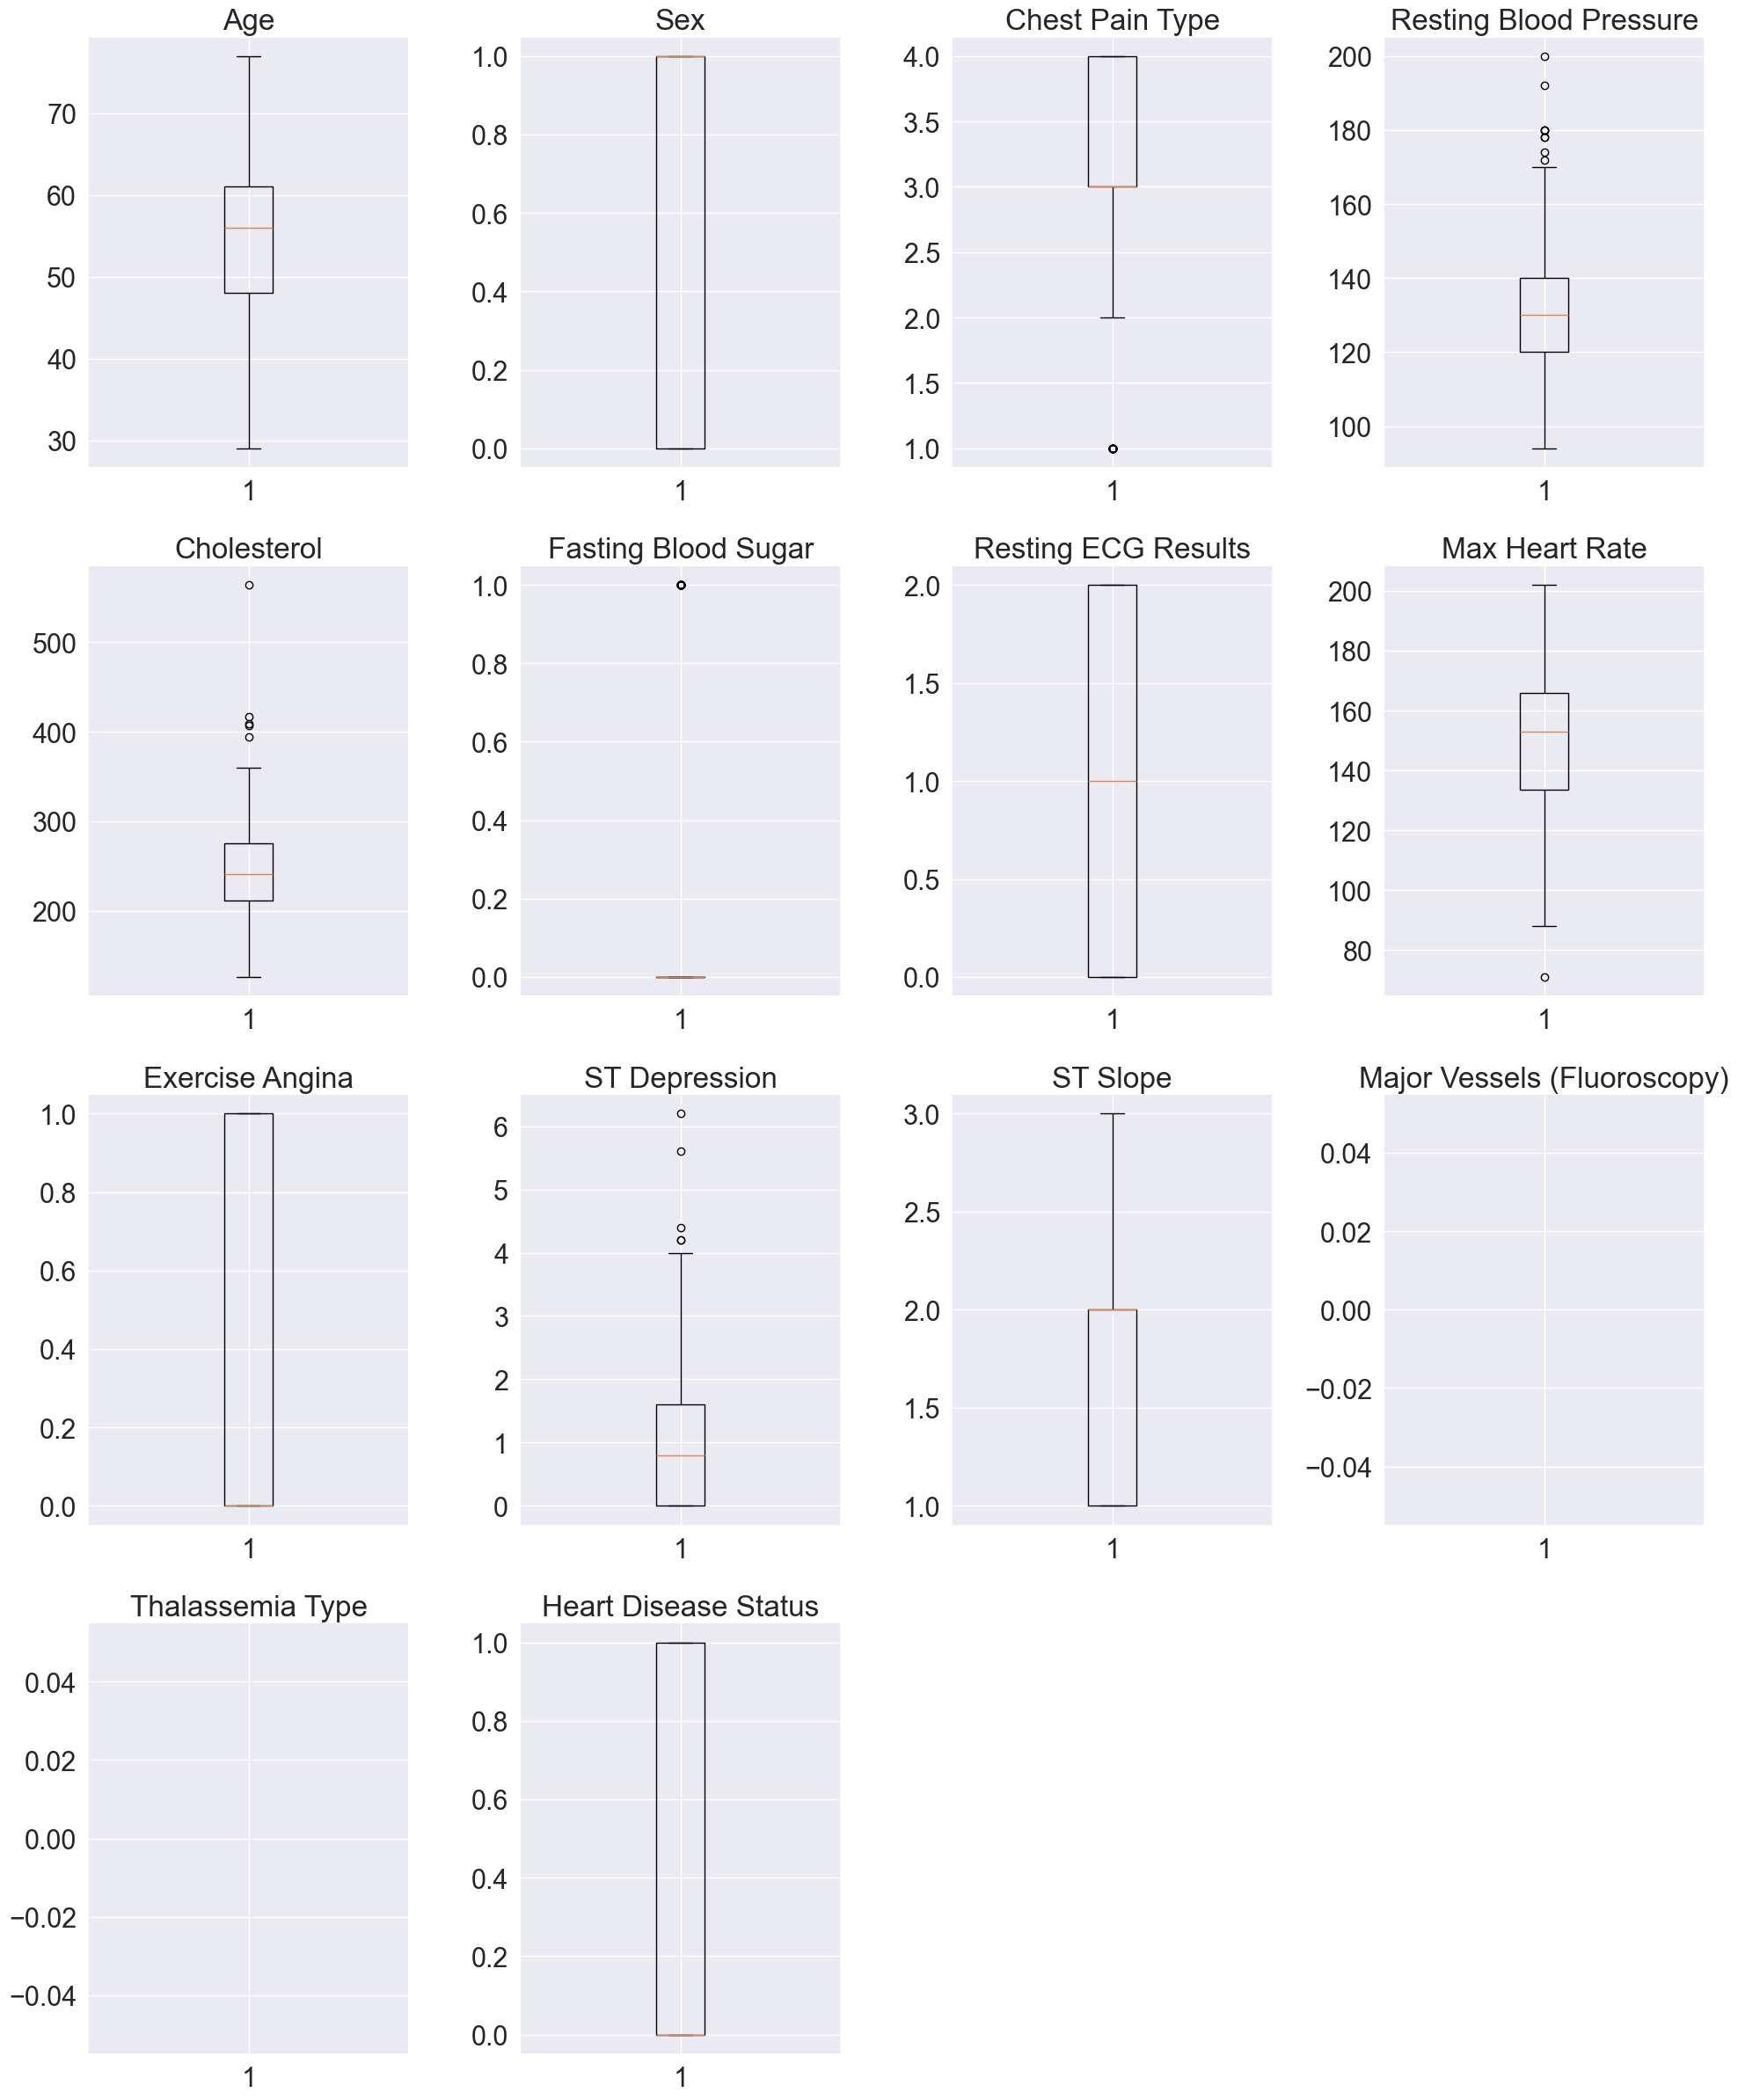

In [51]:
# Outlier detection using boxplots (for all I/R variables)
plt.figure(figsize=(20,30))

for i, variable in enumerate(df): #enumerate is a built-in function in python that allows you to keep track of the number of iterations (loops) in a loop
                     plt.subplot(5,4,i+1) #provides a way to plot multiple plots on a single figure
                     plt.boxplot(df[variable],whis=1.5)
                     plt.tight_layout()
                     plt.title(variable)
                    
plt.show()


### Very Few Outliers Detected

## Bivariate Analysis

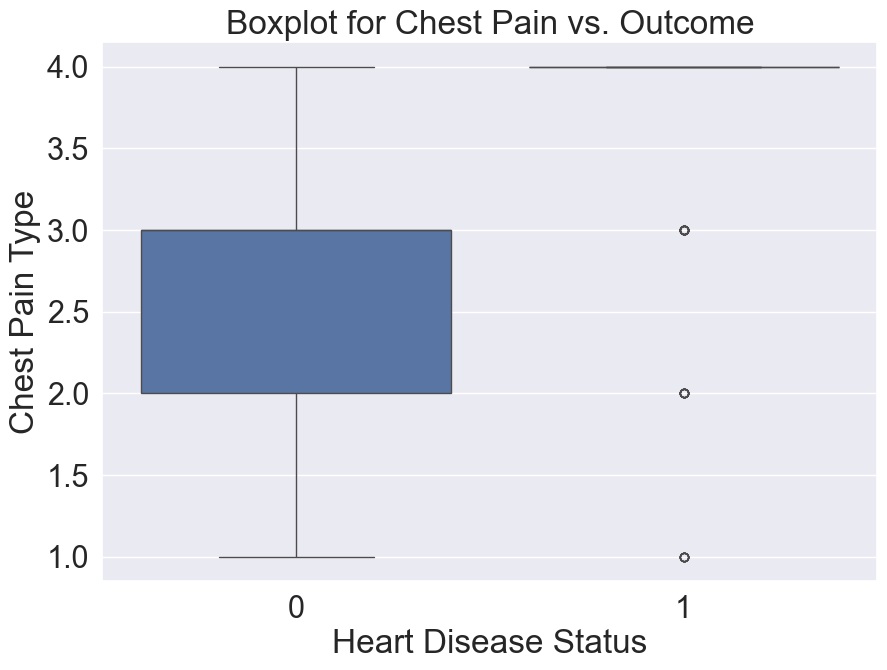

In [52]:
# Boxplot with DV and 1 IV
# sns.boxplot(x = "categorical_var", y = "numeric_var", data = df)
# plt.title('graph_title')
# plt.show()

plt.figure(figsize=(10,7))
sns.boxplot(x = "Heart Disease Status", y = "Chest Pain Type", data = df)
plt.title('Boxplot for Chest Pain vs. Outcome')
plt.show()

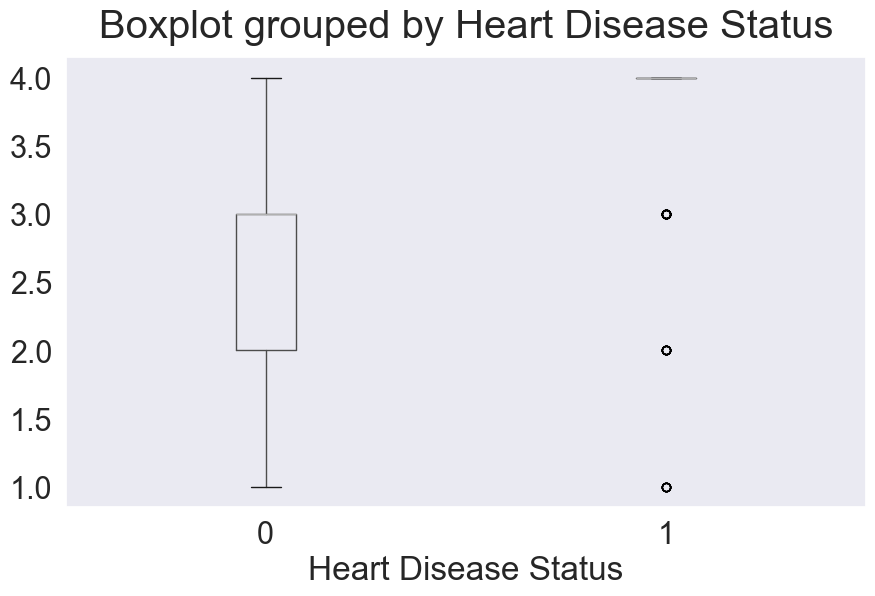

In [53]:
ttest_boxplot = df.boxplot(column='Chest Pain Type', by='Heart Disease Status', figsize=(10, 6), grid=False);
ttest_boxplot.set_title('');
ttest_boxplot.set_ylabel('');
plt.show()

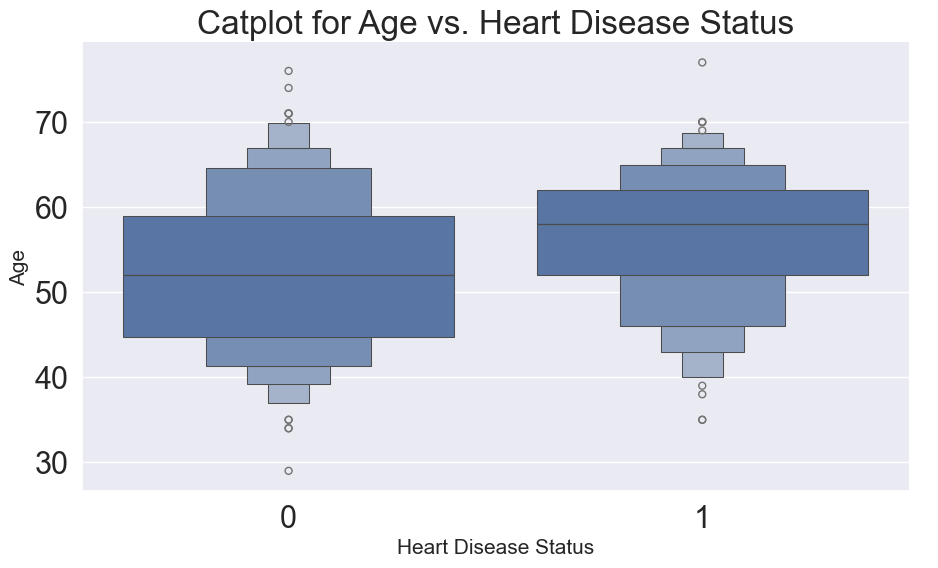

In [54]:
# Catplot
sns.catplot(x="Heart Disease Status", y="Age", data=df, kind='boxen', height=6, aspect=1.6, estimator=np.mean);
figsize=(10, 6)
plt.xlabel('Heart Disease Status', fontsize=15);
plt.title('Catplot for Age vs. Heart Disease Status')
plt.ylabel('Age', fontsize=15);
plt.show()

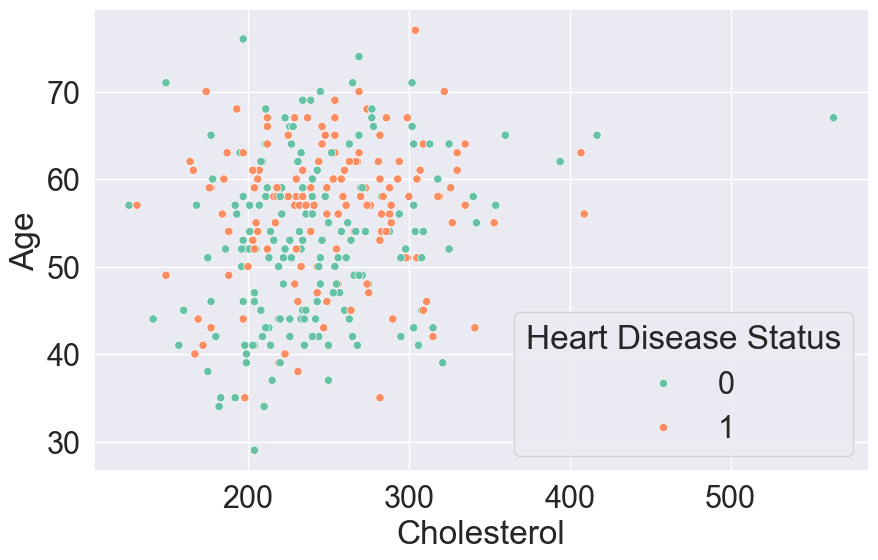

In [55]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Cholesterol', y='Age', hue='Heart Disease Status', data=df, palette='Set2')
plt.show()

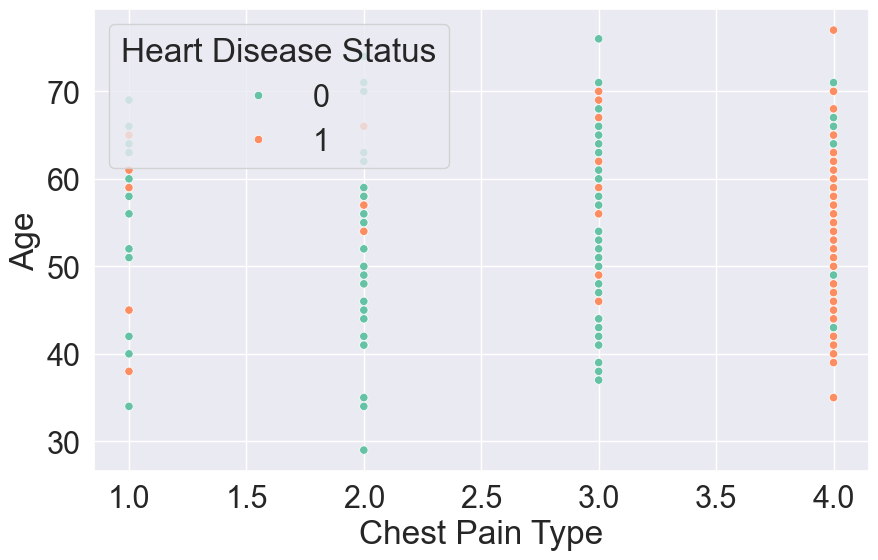

In [56]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Chest Pain Type', y='Age', hue='Heart Disease Status', data=df, palette='Set2')
plt.show()

In [57]:
# View Outcome column
df['Heart Disease Status']

0      0
1      1
2      1
3      0
4      0
      ..
298    1
299    1
300    1
301    1
302    0
Name: Heart Disease Status, Length: 303, dtype: int64

In [58]:
# Map 0's and 1's to 'No Heart Disease' and 'Heart Disease', respectively
df['Heart Disease Status']=df['Heart Disease Status'].map({0:'No Heart Disease', 1:'Heart Disease'})

In [59]:
# After running code above, 0's become 'No Heart Disease', 1's become 'Heart Disease'
df['Heart Disease Status']

0      No Heart Disease
1         Heart Disease
2         Heart Disease
3      No Heart Disease
4      No Heart Disease
             ...       
298       Heart Disease
299       Heart Disease
300       Heart Disease
301       Heart Disease
302    No Heart Disease
Name: Heart Disease Status, Length: 303, dtype: object

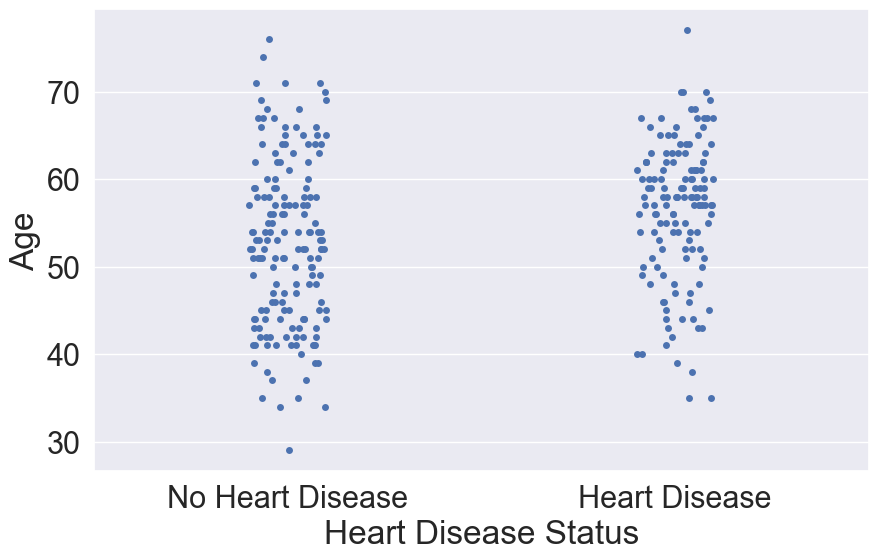

In [60]:
plt.figure(figsize=(10,6))
sns.stripplot(data=df, x='Heart Disease Status', y='Age', jitter=True);
plt.show();

### Analyzing these variables against the target variable (Heart Disease Status) provides excellent insights. From the chest pain analysis, it can be observed that patients diagnosed with heart disease cluster greatly around Type 4 Chest Pain (Asymptomatic), demonstrating the idea that those who are at risk for cardiac disease may lack easily observable symptoms. When age is analyzed alongside one's heart disease status, a clear risk acceleration is presented, with there being a highly concentrated distribution of positive diagnoses between the ages of 50 and 60. There is also a lack of linear separation between cholesterol and one's heart disease status, showing how traditional linear algorithms will likely find trouble identifiying whether one has a heart disease or not.

In [61]:
# To map values back into numbers
df['Heart Disease Status']=df['Heart Disease Status'].map({'No Heart Disease':0, 'Heart Disease':1})
plt.show();

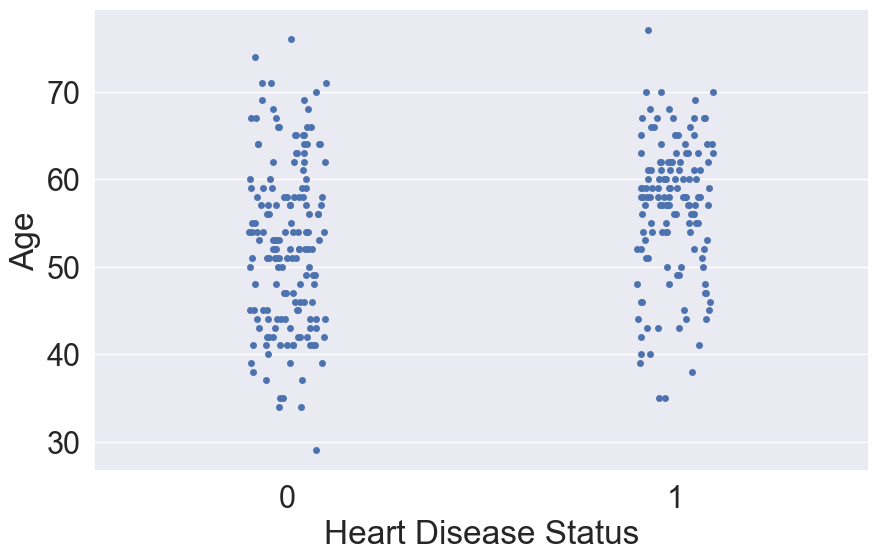

In [62]:
# Rerun the stripplot to see the x-axis labels are now 0 and 1 again
plt.figure(figsize=(10,6))
sns.stripplot(data=df, x='Heart Disease Status', y='Age', jitter=True);
plt.show()

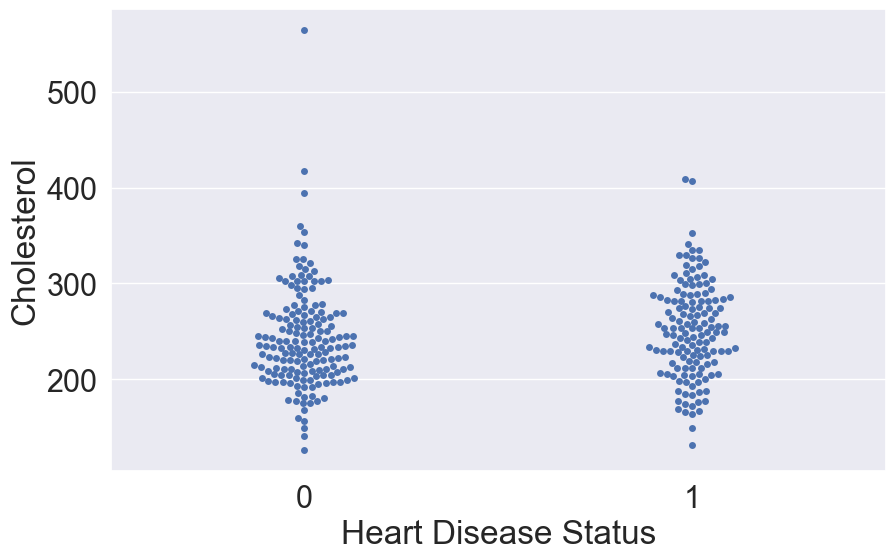

In [63]:
# Create swarm plot
plt.figure(figsize=(10,6))
sns.swarmplot(data=df, x='Heart Disease Status', y='Cholesterol');
plt.show();

# Outcome

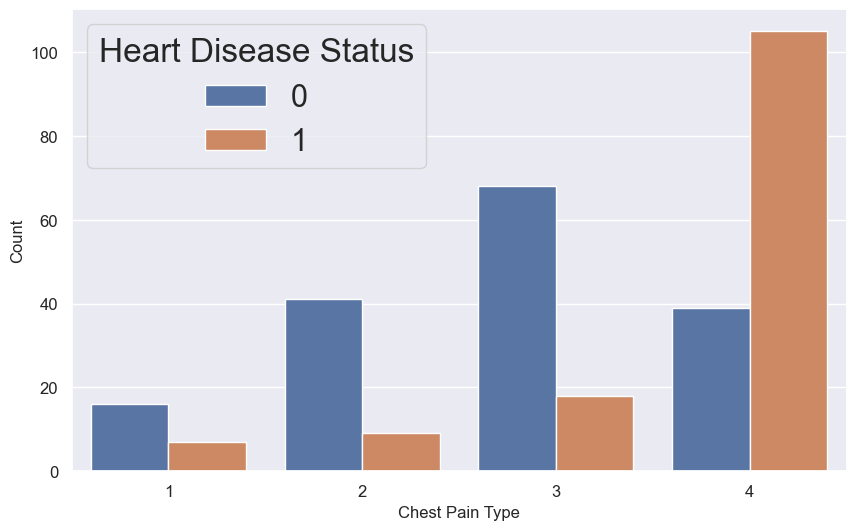

In [64]:
# Create countplot
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Chest Pain Type', hue='Heart Disease Status')

plt.xticks(fontsize=12)  # Smaller x-axis tick labels
plt.yticks(fontsize=12)  # Smaller y-axis tick labels

plt.xlabel('Chest Pain Type', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.show()

## One-Hot Encoding

In [65]:
# Converting categorical variables into binary vectors, where each category becomes a new feature with values of 0 or 1

# Let's create a fake dataframe simply looking at colors:

df_example = pd.DataFrame({'Color': ['Red', 'Blue', 'Green', 'Red', 'Blue']})
df_example


,Color
0,Red
1,Blue
2,Green
3,Red
4,Blue


In [66]:
# Import OneHot encoder
from sklearn.preprocessing import OneHotEncoder

# Initialize One-HotEncoder
encoder = OneHotEncoder()

# Perform encoding
encoded_df = encoder.fit_transform(df_example[['Color']])

# Convert encoded data to a pandas DataFrame
encoded_df = pd.DataFrame(encoded_df.toarray(), columns=encoder.get_feature_names_out(['Color']))

# Concatenate the original data with the encoded data
data_encoded = pd.concat([df_example, encoded_df], axis=1)

print(data_encoded)

   Color  Color_Blue  Color_Green  Color_Red
0    Red       0.000        0.000      1.000
1   Blue       1.000        0.000      0.000
2  Green       0.000        1.000      0.000
3    Red       0.000        0.000      1.000
4   Blue       1.000        0.000      0.000


## IMPORTANT: ONE-HOT ENCODING CATEGORICAL VARIABLES

In [67]:
# One-hot encode multi-category variables such as Chest Pain Type and Resting ECG Results, dropping the first category to avoid redundant columns
df = pd.get_dummies(df, columns=['Chest Pain Type', 'Resting ECG Results', 'Thalassemia Type'], drop_first=True)

## Supervised Machine Learning

In [68]:
# Import additional libraries needed for machine learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import tree

# Libraries for model tuning and evaluation metrics
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV

# Decision Tree

In [69]:
# Separate Outcome or Target variable from the predictors

X = df.drop('Heart Disease Status',axis=1)    # Replace 'Outcome' with your target variable name
y = df['Heart Disease Status'].astype('int64') # Replace 'Outcome' with your target variable name

# We used .astype ('int64) above to convert target to integers since some functions might not work with boolean type

In [70]:
# Split the data into training and test sets

X_train, X_test, y_train, y_test =train_test_split(X, y, test_size=0.3, random_state=1)
# random state controls shuffling before applying split; shuffling is default; stratify allows shuffle by class
print(X_train.shape, X_test.shape)

(212, 17) (91, 17)


In [71]:
# Import a library to automatically compute class weights based on inverse frequency:
from sklearn.utils.class_weight import compute_class_weight

# Compute weights automatically
class_weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)

# Convert to dictionary {class_label: weight}
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

# Use computed weights in the classifier
dtree_base = DecisionTreeClassifier(random_state=1, class_weight=class_weight_dict)
dtree_base.fit(X_train, y_train)

DecisionTreeClassifier(class_weight={0: np.float64(0.9217391304347826),
                                     1: np.float64(1.092783505154639)},
                       random_state=1)

In [72]:
#  Function to calculate different metric scores - Accuracy, Recall, Preceision, and F1 Scores

def get_metrics_score(model,flag=True):
    # defining an empty list to store train and test results
    score_list=[] 
    
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    
    train_acc = model.score(X_train,y_train)
    test_acc = model.score(X_test,y_test)
    
    train_recall = metrics.recall_score(y_train,pred_train)
    test_recall = metrics.recall_score(y_test,pred_test)
    # Recall = minimizes false negatives
    
    train_precision = metrics.precision_score(y_train,pred_train)
    test_precision = metrics.precision_score(y_test,pred_test)
    # Precision = minimizes false positives

    train_f1 = metrics.f1_score(y_train,pred_train)
    test_f1 = metrics.f1_score(y_test,pred_test)
    # F1 Score = balances precision and recall
    
    score_list.extend((train_acc,test_acc,train_recall,test_recall,train_precision,test_precision,train_f1,test_f1))
        
    if flag == True: 
        print("Accuracy on training set : ",model.score(X_train,y_train))
        print("Accuracy on test set : ",model.score(X_test,y_test))
        print("Recall on training set : ",metrics.recall_score(y_train,pred_train))
        print("Recall on test set : ",metrics.recall_score(y_test,pred_test))
        print("Precision on training set : ",metrics.precision_score(y_train,pred_train))
        print("Precision on test set : ",metrics.precision_score(y_test,pred_test))
        print("F1 Score on training set : ",metrics.f1_score(y_train,pred_train))
        print("F1 Score on test set : ",metrics.f1_score(y_test,pred_test))
    
    return score_list # returns the list with train and test scores

In [73]:
# Function to make confusion matrix

def make_confusion_matrix(model, y_actual, labels=[1, 0]):
    # Predict using the model
    y_predict = model.predict(X_test)  # <- This should match y_actual's source
    cm = metrics.confusion_matrix(y_actual, y_predict, labels=[0, 1])
    
    # Create a labeled DataFrame for the confusion matrix
    df_cm = pd.DataFrame(cm, index = [i for i in ["Actual - No","Actual - Yes"]],
                              columns = [i for i in ['Predicted - No','Predicted - Yes']])
    
    # Format counts and percentages for annotation
    group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
    group_percentages = ["{0:.2%}".format(value) for value in cm.flatten()/np.sum(cm)]
    
    # Combine into annotation labels
    labels = [f"{v1}\n{v2}" for v1, v2 in zip(group_counts, group_percentages)]
    labels = np.asarray(labels).reshape(2,2)
    
    # Plot the heatmap
    plt.figure(figsize = (10,7))
    sns.heatmap(df_cm, annot=labels, fmt='', cmap='Blues')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show();

Accuracy on training set :  1.0
Accuracy on test set :  0.7802197802197802
Recall on training set :  1.0
Recall on test set :  0.6904761904761905
Precision on training set :  1.0
Precision on test set :  0.8055555555555556
F1 Score on training set :  1.0
F1 Score on test set :  0.7435897435897436


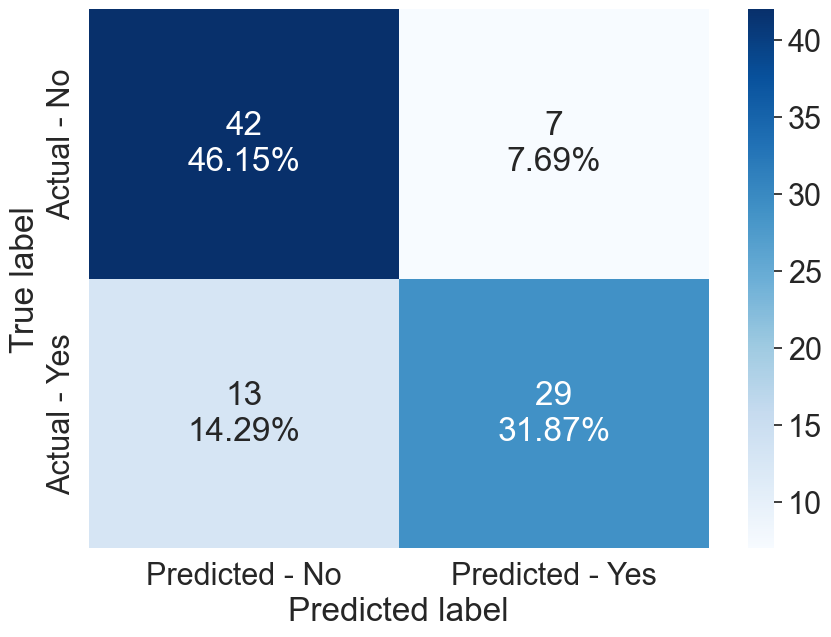

In [74]:
# Calculate metrics for your model
get_metrics_score(dtree_base)

# Create confusion matrix for your mdodel
make_confusion_matrix(dtree_base, y_test)

### Decision Tree overfits right now, will fix in the pruning stage. Recall should be prioritized, as a false negative is far more harmful in a health based scenario than a false positive, while both are still harmful.

In [75]:
column_names = list(df.columns)
column_names.remove('Heart Disease Status')  # As this is the DV                
feature_names = column_names
print(feature_names)

['Age', 'Sex', 'Resting Blood Pressure', 'Cholesterol', 'Fasting Blood Sugar', 'Max Heart Rate', 'Exercise Angina', 'ST Depression', 'ST Slope', 'Major Vessels (Fluoroscopy)', 'Chest Pain Type_2', 'Chest Pain Type_3', 'Chest Pain Type_4', 'Resting ECG Results_1', 'Resting ECG Results_2', 'Thalassemia Type_6.0', 'Thalassemia Type_7.0']


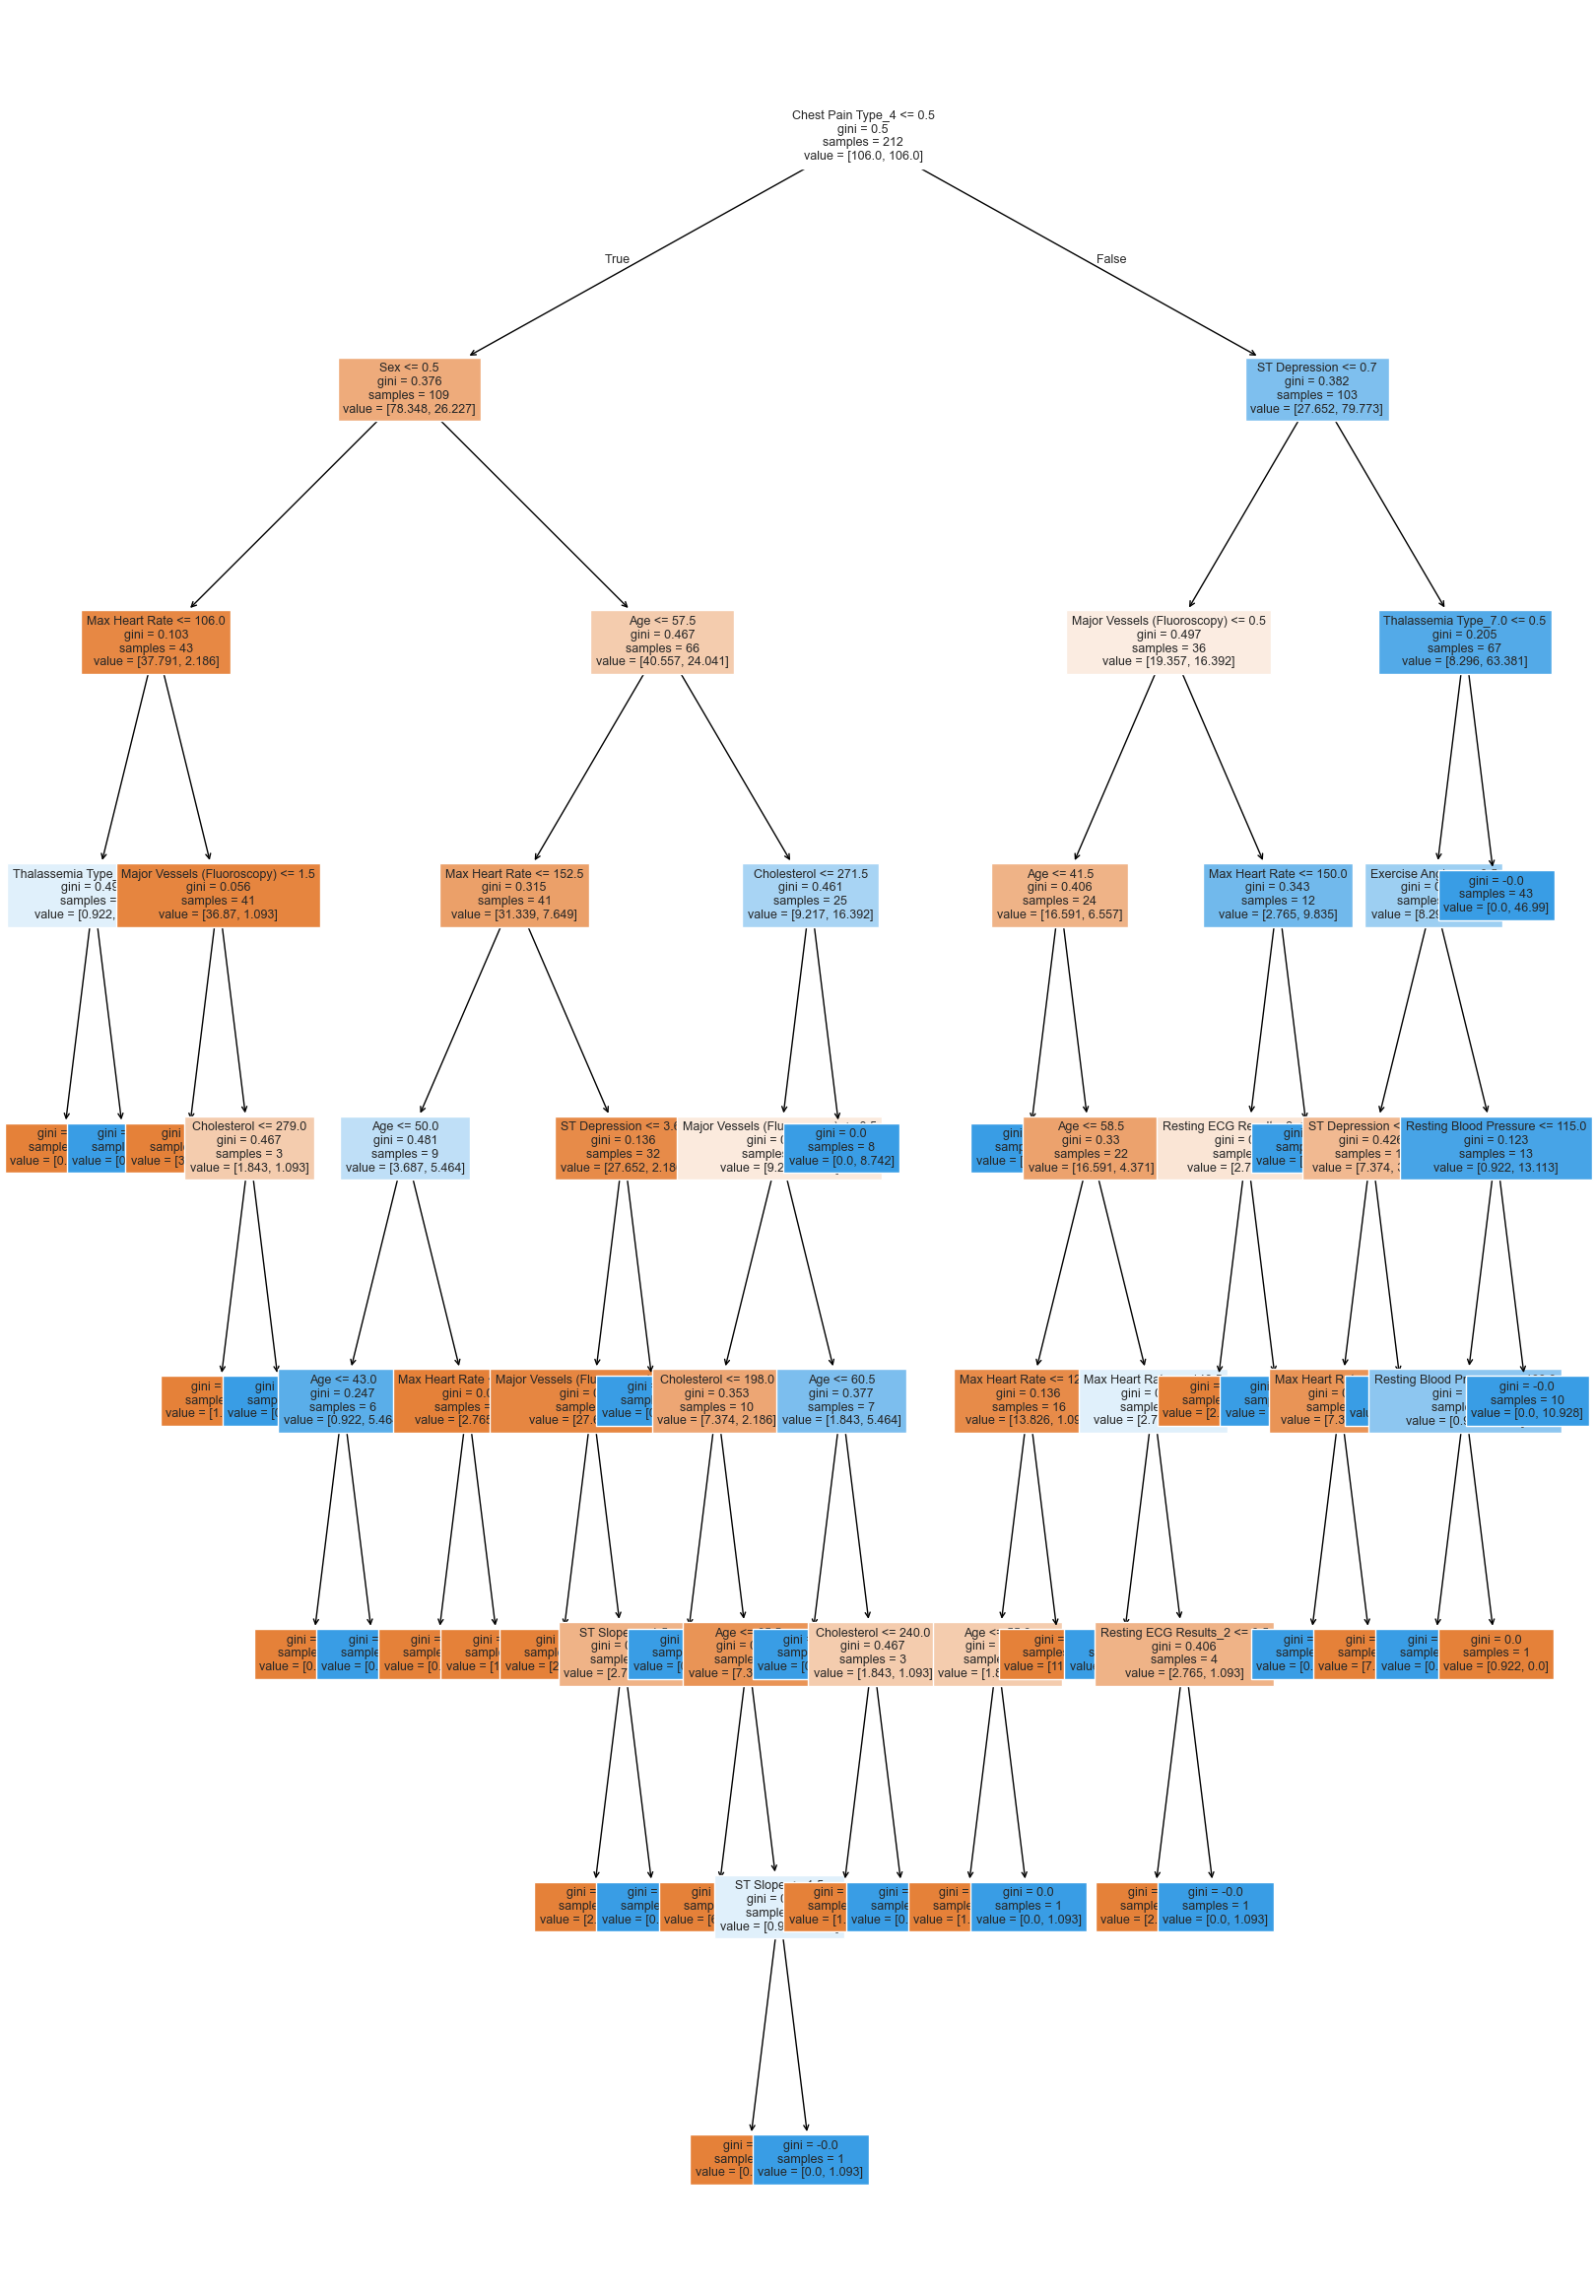

In [76]:
# Visualize decision tree

plt.figure(figsize=(20,30))
out = tree.plot_tree(dtree_base,feature_names=feature_names,filled=True,fontsize=9,node_ids=False,class_names=None,)
# Code below will add arrows to the decision tree split if they are missing
for o in out:
     arrow = o.arrow_patch
     if arrow is not None:
        arrow.set_edgecolor('black')
        arrow.set_linewidth(1)
plt.show()


In [77]:
# Print text report showing the rules of the decision tree

print(tree.export_text(dtree_base,feature_names=feature_names,show_weights=True))


|--- Chest Pain Type_4 <= 0.50
|   |--- Sex <= 0.50
|   |   |--- Max Heart Rate <= 106.00
|   |   |   |--- Thalassemia Type_7.0 <= 0.50
|   |   |   |   |--- weights: [0.92, 0.00] class: 0
|   |   |   |--- Thalassemia Type_7.0 >  0.50
|   |   |   |   |--- weights: [0.00, 1.09] class: 1
|   |   |--- Max Heart Rate >  106.00
|   |   |   |--- Major Vessels (Fluoroscopy) <= 1.50
|   |   |   |   |--- weights: [35.03, 0.00] class: 0
|   |   |   |--- Major Vessels (Fluoroscopy) >  1.50
|   |   |   |   |--- Cholesterol <= 279.00
|   |   |   |   |   |--- weights: [1.84, 0.00] class: 0
|   |   |   |   |--- Cholesterol >  279.00
|   |   |   |   |   |--- weights: [0.00, 1.09] class: 1
|   |--- Sex >  0.50
|   |   |--- Age <= 57.50
|   |   |   |--- Max Heart Rate <= 152.50
|   |   |   |   |--- Age <= 50.00
|   |   |   |   |   |--- Age <= 43.00
|   |   |   |   |   |   |--- weights: [0.92, 0.00] class: 0
|   |   |   |   |   |--- Age >  43.00
|   |   |   |   |   |   |--- weights: [0.00, 5.46] class: 1


### Tree is smaller than the example tree, but this is because there is far less data here, the tree seems to be doing what its supposed to without any pruning so far.

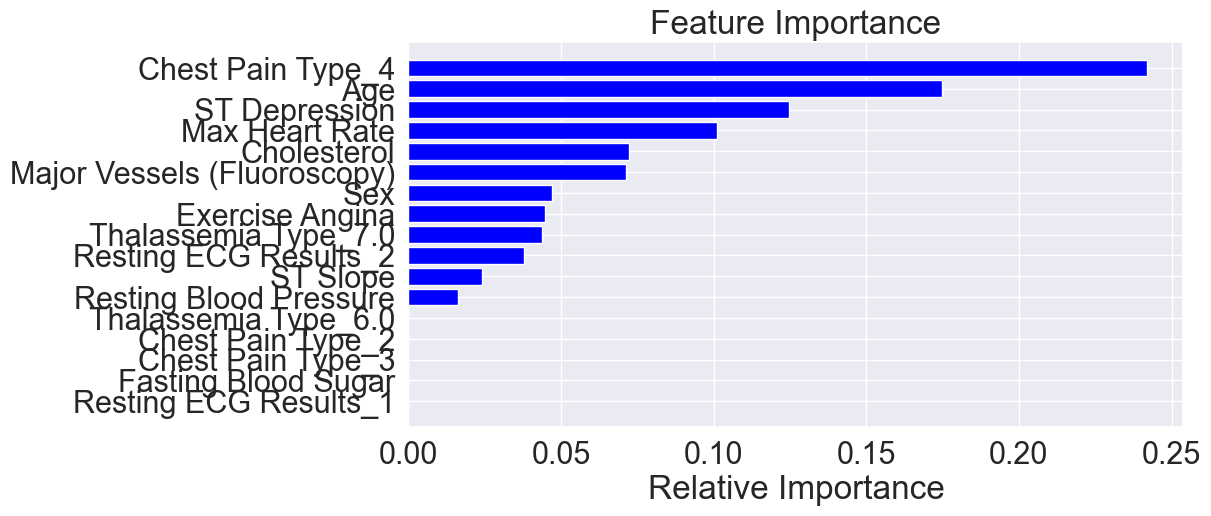

In [78]:
# Example of Feature Importance

importances = dtree_base.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(10,5))
plt.title('Feature Importance')
plt.barh(range(len(indices)), importances[indices], color='blue', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

### Tuned Decision Tree

In [79]:
dtree_tuned = DecisionTreeClassifier(class_weight=class_weight_dict, random_state=1)

# Define hyperparameter grid
parameters = {
    'max_depth': [3, 4, 5, 6],
    'min_samples_leaf': [4, 5, 6, 8, 10],
    'max_leaf_nodes': [6, 8, 10, 12, 15],
    'min_impurity_decrease': [0.001, 0.01, 0.0]
}

# Scoring function
scorer = metrics.make_scorer(metrics.recall_score)

# Grid search

grid_obj = GridSearchCV(dtree_tuned, parameters, scoring=scorer, n_jobs=-1)
grid_obj.fit(X_train, y_train)

# Best estimator
dtree_tuned = grid_obj.best_estimator_
dtree_tuned.fit(X_train, y_train)

DecisionTreeClassifier(class_weight={0: np.float64(0.9217391304347826),
                                     1: np.float64(1.092783505154639)},
                       max_depth=3, max_leaf_nodes=8,
                       min_impurity_decrease=0.01, min_samples_leaf=4,
                       random_state=1)

Accuracy on training set :  0.8254716981132075
Accuracy on test set :  0.7912087912087912
Recall on training set :  0.845360824742268
Recall on test set :  0.7380952380952381
Precision on training set :  0.7884615384615384
Precision on test set :  0.7948717948717948
F1 Score on training set :  0.8159203980099502
F1 Score on test set :  0.7654320987654321


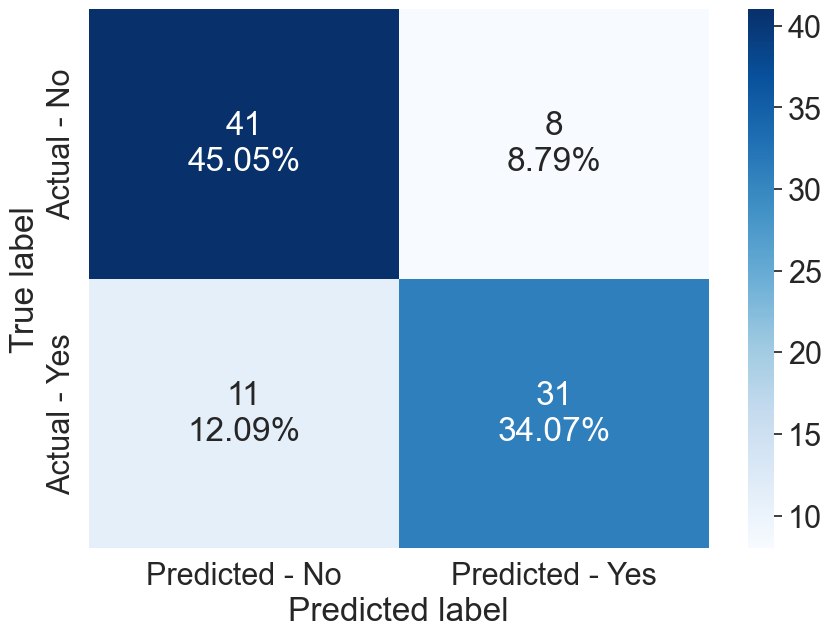

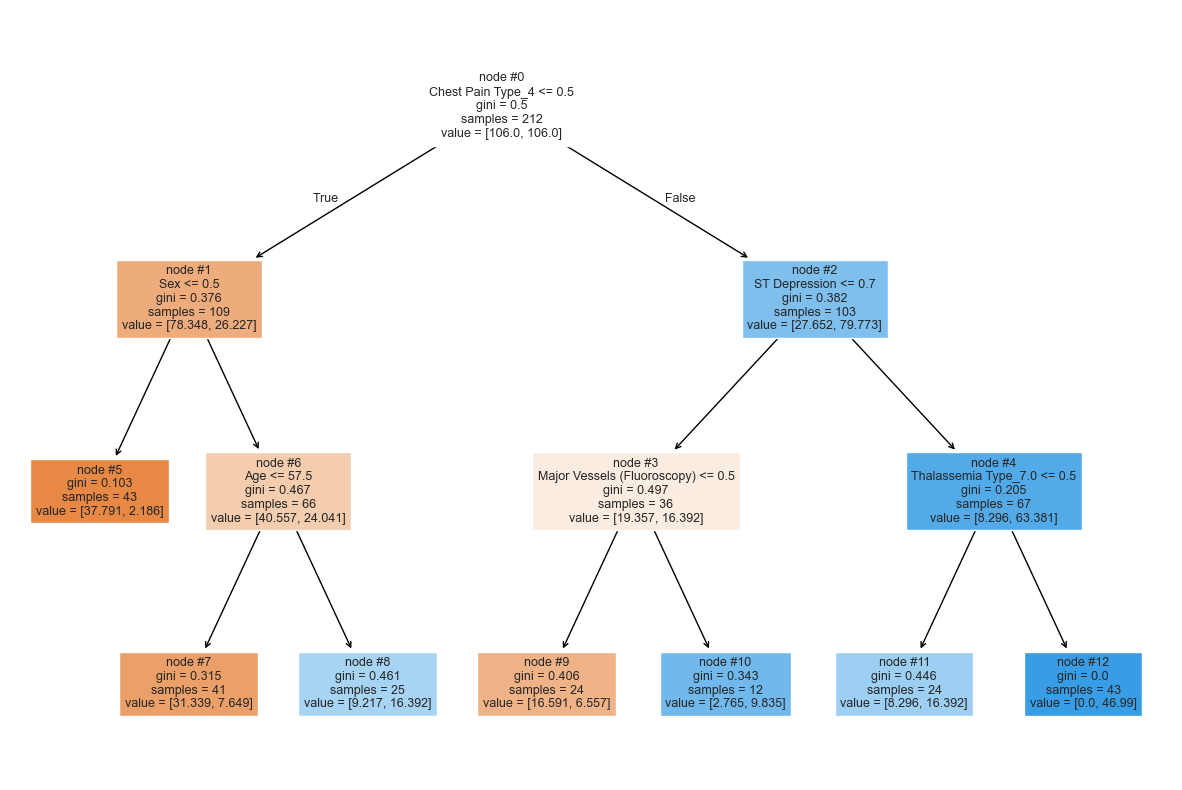

In [80]:
# View metrics score
get_metrics_score(dtree_tuned)

# Create confusion matrix
make_confusion_matrix(dtree_tuned,y_test)

# Visualize tuned decision tree
plt.figure(figsize=(15,10))
out = tree.plot_tree(dtree_tuned,feature_names=feature_names,filled=True,fontsize=9,node_ids=True,class_names=None)
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black')
        arrow.set_linewidth(1)
plt.show()

In [81]:
# Print text report showing the rules of the tuned decision tree
print(tree.export_text(dtree_tuned,feature_names=feature_names,show_weights=False))

|--- Chest Pain Type_4 <= 0.50
|   |--- Sex <= 0.50
|   |   |--- class: 0
|   |--- Sex >  0.50
|   |   |--- Age <= 57.50
|   |   |   |--- class: 0
|   |   |--- Age >  57.50
|   |   |   |--- class: 1
|--- Chest Pain Type_4 >  0.50
|   |--- ST Depression <= 0.70
|   |   |--- Major Vessels (Fluoroscopy) <= 0.50
|   |   |   |--- class: 0
|   |   |--- Major Vessels (Fluoroscopy) >  0.50
|   |   |   |--- class: 1
|   |--- ST Depression >  0.70
|   |   |--- Thalassemia Type_7.0 <= 0.50
|   |   |   |--- class: 1
|   |   |--- Thalassemia Type_7.0 >  0.50
|   |   |   |--- class: 1



### Tuned Decision Tree: After many attempts at tuning I believe the decision tree is about as good as it can be, Recall score is hovering around 70-80 percent for the test set, so I will likely not choose this model.

## Bagging Classifier

Accuracy on training set :  0.9952830188679245
Accuracy on test set :  0.8241758241758241
Recall on training set :  0.9896907216494846
Recall on test set :  0.7380952380952381
Precision on training set :  1.0
Precision on test set :  0.8611111111111112
F1 Score on training set :  0.9948186528497409
F1 Score on test set :  0.7948717948717948


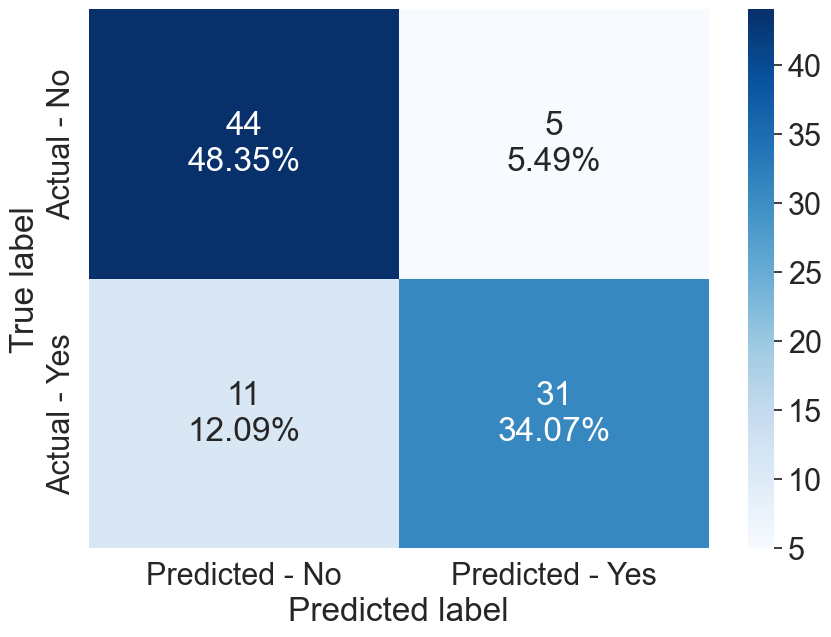

In [82]:
# Fit the model
bagging_base = BaggingClassifier(random_state=1)
bagging_base.fit(X_train,y_train)

# Calculate metrics
get_metrics_score(bagging_base)

# Create the confusion matrix
make_confusion_matrix(bagging_base,y_test)

## Tuned Bagging Classifier

In [83]:

# Define base BaggingClassifier
bagging_tuned = BaggingClassifier(random_state=1)

# Hyperparameter grid
parameters = {
    'max_samples': [0.5, 0.6, 0.7, 0.8],
    'max_features': [0.5, 0.6, 0.7, 0.8],
    'n_estimators': [50, 80, 100, 150],
}

# Use recall as scoring metric
recall_scorer = metrics.make_scorer(metrics.recall_score)

# Setup GridSearchCV with parallel jobs and 5-fold CV
grid_obj = GridSearchCV(bagging_tuned, parameters, scoring=recall_scorer, cv=5, n_jobs=-1)

# Fit grid search
grid_obj.fit(X_train, y_train)

# Best estimator from grid search
bagging_tuned = grid_obj.best_estimator_

# Fit the best model on full training data
bagging_tuned.fit(X_train, y_train)

BaggingClassifier(max_features=0.5, max_samples=0.5, n_estimators=150,
                  random_state=1)

Accuracy on training set :  0.9764150943396226
Accuracy on test set :  0.8461538461538461
Recall on training set :  0.9587628865979382
Recall on test set :  0.7857142857142857
Precision on training set :  0.9893617021276596
Precision on test set :  0.868421052631579
F1 Score on training set :  0.9738219895287958
F1 Score on test set :  0.825


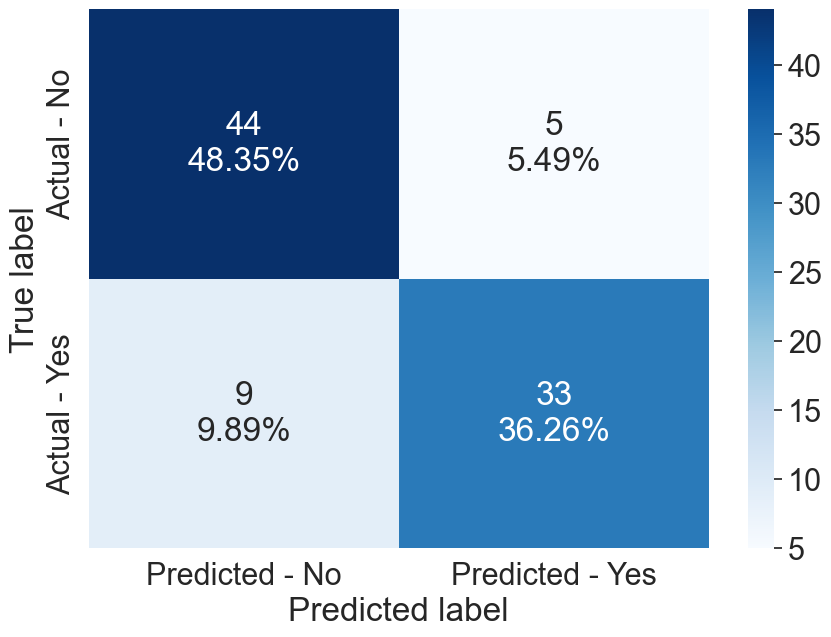

In [84]:
get_metrics_score(bagging_tuned)

make_confusion_matrix(bagging_tuned,y_test)

### Bagging Classifier: Tuned Bagging Classifier has higher recall levels and training accuracy than the Tuned Decision Tree, but I will have to check the Random Forest model to compare more.

## Random Forest

Accuracy on training set :  1.0
Accuracy on test set :  0.8241758241758241
Recall on training set :  1.0
Recall on test set :  0.7619047619047619
Precision on training set :  1.0
Precision on test set :  0.8421052631578947
F1 Score on training set :  1.0
F1 Score on test set :  0.8


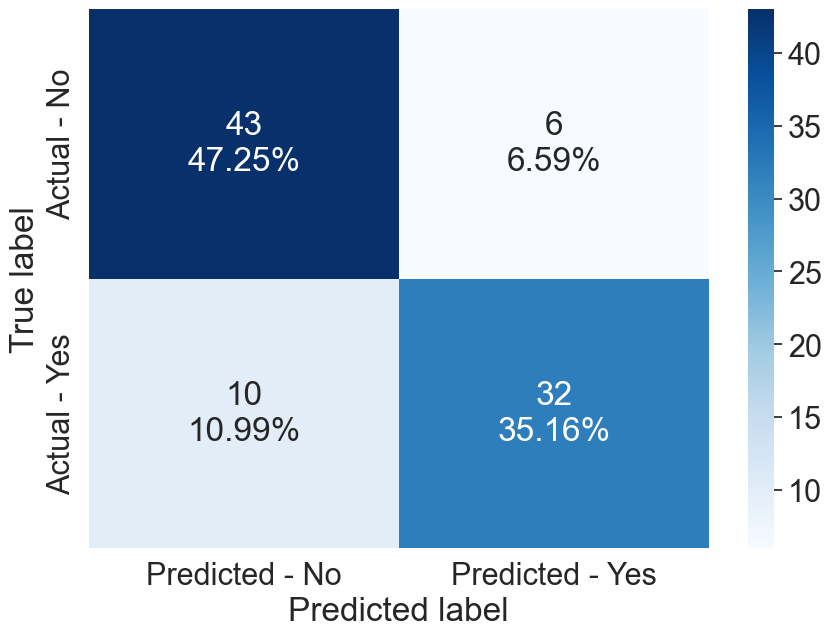

In [85]:
# Fit the model
rf_base = RandomForestClassifier(random_state=1)
rf_base.fit(X_train,y_train)

# Calculate metrics
get_metrics_score(rf_base)

# Create the confusion matrix
make_confusion_matrix(rf_base,y_test)

## Tuned Random Forest

In [86]:
%%time

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import metrics
import numpy as np

rf_tuned = RandomForestClassifier(class_weight={0:0.35,1:0.65}, random_state=1)

parameters = {
    'n_estimators': [150, 200, 250],           
    'max_depth': [9, 11, 13, None],            
    'min_samples_leaf': [2, 3, 4],             
    'max_features': ['sqrt', 0.35, 0.4, 0.45]  
}

scorer = metrics.make_scorer(metrics.recall_score)

grid_obj = GridSearchCV(rf_tuned, parameters, scoring=scorer, cv=5, n_jobs=-1)
grid_obj.fit(X_train, y_train)

rf_tuned = grid_obj.best_estimator_
rf_tuned.fit(X_train, y_train)

CPU times: user 532 ms, sys: 37.3 ms, total: 569 ms
Wall time: 10.8 s


RandomForestClassifier(class_weight={0: 0.35, 1: 0.65}, max_depth=9,
                       min_samples_leaf=3, n_estimators=200, random_state=1)

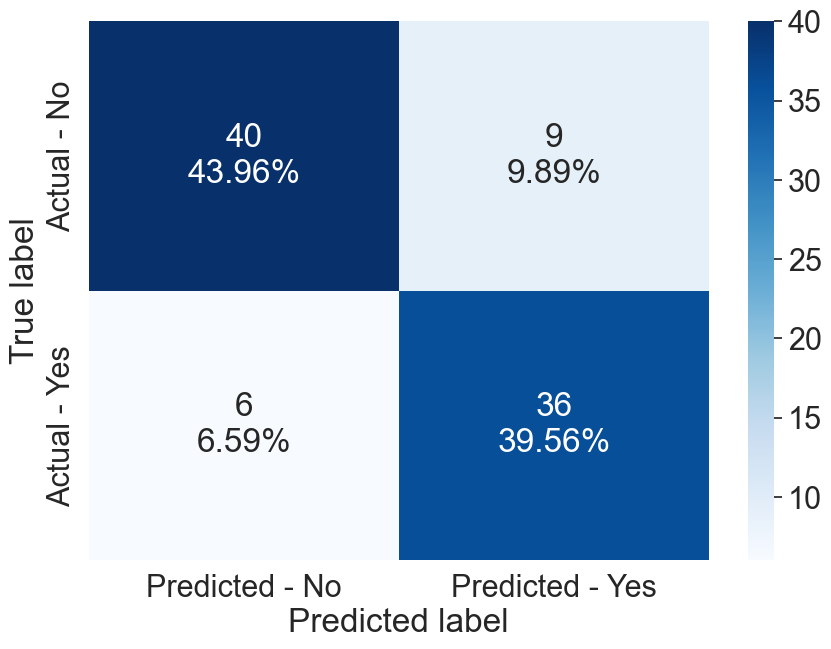

Accuracy on training set :  0.9433962264150944
Accuracy on test set :  0.8351648351648352
Recall on training set :  0.9690721649484536
Recall on test set :  0.8571428571428571
Precision on training set :  0.912621359223301
Precision on test set :  0.8
F1 Score on training set :  0.94
F1 Score on test set :  0.8275862068965517


[0.9433962264150944,
 0.8351648351648352,
 0.9690721649484536,
 0.8571428571428571,
 0.912621359223301,
 0.8,
 0.94,
 0.8275862068965517]

In [87]:

#Creating confusion matrix
make_confusion_matrix(rf_tuned,y_test)
#Calculating metrics score
get_metrics_score(rf_tuned)


## Comparing Supervised ML Classification Models

In [88]:
# Identify the models to compare
models = [dtree_base, dtree_tuned, bagging_base, bagging_tuned, rf_base, rf_tuned]

# Define empty lists to store results
acc_train = []
acc_test = []
recall_train = []
recall_test = []
precision_train = []
precision_test = []
f1_train = []
f1_test = []

# Loop through all models to collect metrics (Accuracy, Recall, Precision, F1)
for model in models:
    scores = get_metrics_score(model, False)
    acc_train.append(scores[0])
    acc_test.append(scores[1])
    recall_train.append(scores[2])
    recall_test.append(scores[3])
    precision_train.append(scores[4])
    precision_test.append(scores[5])
    f1_train.append(scores[6])
    f1_test.append(scores[7])

In [89]:
# Compare models on evaluation metrics

comparison_frame = pd.DataFrame({
    'Model': ['Decision Tree', 'Tuned Decision Tree', 'Bagging Classifier', 'Tuned Bagging Classifier', 'Random Forest', 'Tuned Random Forest'],
    'Train_Accuracy': acc_train,
    'Test_Accuracy': acc_test,
    'Train_Recall': recall_train,
    'Test_Recall': recall_test,
    'Train_Precision': precision_train,
    'Test_Precision': precision_test,
    'Train_F1': f1_train,
    'Test_F1': f1_test
})

# Sort models in decreasing order of most important metric
comparison_frame_sorted = comparison_frame.sort_values(by='Test_Recall', ascending=False)

# Set display options to avoid wrapping wide DataFrames
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

# Print sorted DataFrame
print(comparison_frame_sorted)

                      Model  Train_Accuracy  Test_Accuracy  Train_Recall  Test_Recall  Train_Precision  Test_Precision  Train_F1  Test_F1
5       Tuned Random Forest           0.943          0.835         0.969        0.857            0.913           0.800     0.940    0.828
3  Tuned Bagging Classifier           0.976          0.846         0.959        0.786            0.989           0.868     0.974    0.825
4             Random Forest           1.000          0.824         1.000        0.762            1.000           0.842     1.000    0.800
1       Tuned Decision Tree           0.825          0.791         0.845        0.738            0.788           0.795     0.816    0.765
2        Bagging Classifier           0.995          0.824         0.990        0.738            1.000           0.861     0.995    0.795
0             Decision Tree           1.000          0.780         1.000        0.690            1.000           0.806     1.000    0.744


## Viewing Most Important Features so Far


Gini Importance - Tuned Random Forest

                             Importance
ST Depression                     0.152
Chest Pain Type_4                 0.129
Thalassemia Type_7.0              0.115
Max Heart Rate                    0.105
Major Vessels (Fluoroscopy)       0.101
Age                               0.073
Exercise Angina                   0.062
Cholesterol                       0.059
Resting Blood Pressure            0.056
ST Slope                          0.050
Sex                               0.048
Chest Pain Type_3                 0.020
Resting ECG Results_2             0.014
Chest Pain Type_2                 0.011
Fasting Blood Sugar               0.005
Thalassemia Type_6.0              0.001
Resting ECG Results_1             0.000


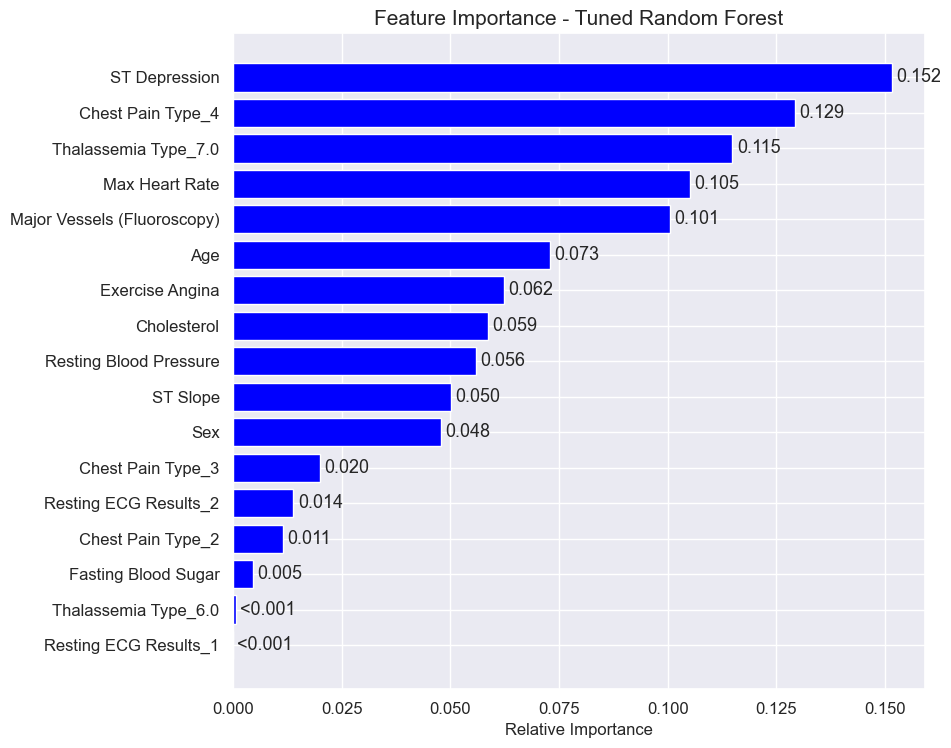

In [90]:
# Step 0: Set your best model 
best_model = rf_tuned      # Change this as needed

# Step 1: Feature names (assumes X_train is a pandas DataFrame)
feature_names = X_train.columns.tolist()

# Step 2: Human-readable name mapping
model_name_map = {
    id(dtree_tuned): "Tuned Decision Tree",
    id(bagging_tuned): "Tuned Bagging Classifier",
    id(rf_tuned): "Tuned Random Forest"
}

model_name = model_name_map.get(id(best_model), type(best_model).__name__)

# Step 3: Get feature importances
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
elif hasattr(best_model, "estimators_"):
    importances = np.mean(
        [est.feature_importances_ for est in best_model.estimators_],
        axis=0
    )
else:
    raise ValueError("This model does not support feature importances.")

# Step 4: Print Gini importances as a DataFrame
gini_df = pd.DataFrame(importances, columns=["Importance"], index=feature_names)
gini_df = gini_df.sort_values(by="Importance", ascending=False)
print(f"\nGini Importance - {model_name}\n")
print(gini_df)

# Step 5: Plot feature importance
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 8))
plt.title(f'Feature Importance - {model_name}', fontsize=15)
plt.barh(range(len(indices)), importances[indices], color='blue', align='center')

# Adjust axis labels and tick font sizes
plt.yticks(range(len(indices)), [feature_names[i] for i in indices], fontsize=12)
plt.xticks(fontsize=12)
plt.xlabel('Relative Importance', fontsize=12)

# Annotate each bar with importance value
for i, idx in enumerate(indices):
    val = importances[idx]
    label = "<0.001" if val < 0.001 else f"{val:.3f}"
    plt.text(val + 0.001, i, label, va='center', fontsize=13)

plt.tight_layout()
plt.gca().invert_yaxis()
plt.show();

### Important Insight: 
* ST Depression, Asymptomatic Chest Pain, and Reversible Thalassemia complications are among the most important features when predicting heart disease. All of these features are mainly induced by exercise or stress, and also can be found in asymptomatic patients. This demonstrates that heart disease can be silent, and depends more on stress related results on the heart rather than one's demographic.
* Within this dataset, asymptomatic Chest Pain is primarily important among all other Chest Pain types in predicting heart disease.

# **Optional Machine Learning Models**

## Logistic Regression

In [91]:
# Import additional library
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

In [92]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Clean out the NaNs for Train and Test sets separately
train_clean_indices = X_train.dropna().index
X_train_clean = X_train.loc[train_clean_indices]
y_train_clean = y_train.loc[train_clean_indices]

test_clean_indices = X_test.dropna().index
X_test_clean = X_test.loc[test_clean_indices]
y_test_clean = y_test.loc[test_clean_indices]

# 2. Standardize the features using the clean data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# 3. Initialize the logistic regression model
log_reg = LogisticRegression(
    solver='newton-cg',
    max_iter=1000,
    penalty=None,           # Regularization
    verbose=True,           # Shows optimization progress
    n_jobs=-1,              # Use all CPU cores
    random_state=0
)

In [93]:
def get_metrics_score(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))

In [94]:
# Fit the model to the training data
log_reg.fit(X_train_scaled, y_train_clean)

# Predict probabilities for ROC curve
y_probs = log_reg.predict_proba(X_test_scaled)[:, 1]

Newton-CG iter = 0
  Check Convergence
    max |gradient| <= tol: 0.24318951271928627 <= 0.0001 False
Newton-CG iter = 1
  Check Convergence
    max |gradient| <= tol: 0.08013479068273195 <= 0.0001 False
Newton-CG iter = 2
  Check Convergence
    max |gradient| <= tol: 0.03576745709949954 <= 0.0001 False
Newton-CG iter = 3
  Check Convergence
    max |gradient| <= tol: 0.009614223095116853 <= 0.0001 False
Newton-CG iter = 4
  Check Convergence
    max |gradient| <= tol: 0.00205831141516101 <= 0.0001 False
Newton-CG iter = 5
  Check Convergence
    max |gradient| <= tol: 0.00038960103261512235 <= 0.0001 False
Newton-CG iter = 6
  Check Convergence
    max |gradient| <= tol: 0.0001427010475719073 <= 0.0001 False
Newton-CG iter = 7
  Check Convergence
    max |gradient| <= tol: 5.251046211646057e-05 <= 0.0001 True
  Solver did converge at loss = 0.3443855917745654.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
/Users/rishideshpande/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/rishideshpande/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/rishideshpande/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/rishideshpande/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:721: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/rishideshpande/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model

In [95]:
def get_metrics_score(model, X_train, y_train, X_test, y_test):
    # Predict on train and test
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Print results
    print("Model Performance")
    print("-" * 40)
    print("{:<15} {:<10} {:<10}".format("Metric", "Train", "Test"))
    print("-" * 40)
    print("{:<15} {:<10.2f} {:<10.2f}".format("Accuracy", 
          accuracy_score(y_train, y_pred_train), accuracy_score(y_test, y_pred_test)))
    print("{:<15} {:<10.2f} {:<10.2f}".format("Precision", 
          precision_score(y_train, y_pred_train), precision_score(y_test, y_pred_test)))
    print("{:<15} {:<10.2f} {:<10.2f}".format("Recall", 
          recall_score(y_train, y_pred_train), recall_score(y_test, y_pred_test)))
    print("{:<15} {:<10.2f} {:<10.2f}".format("F1 Score", 
          f1_score(y_train, y_pred_train), f1_score(y_test, y_pred_test)))
    print("-" * 40)

In [96]:
def make_confusion_matrix(model, X_test, y_actual, labels=[0, 1]):
    # Predict using the model
    y_predict = model.predict(X_test)
    
    # Compute confusion matrix
    cm = metrics.confusion_matrix(y_actual, y_predict, labels=labels)
    
    # Create labeled DataFrame
    df_cm = pd.DataFrame(
        cm,
        index=["Actual - No", "Actual - Yes"],
        columns=["Predicted - No", "Predicted - Yes"]
    )
    
    # Prepare annotation labels (counts + percentages)
    group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
    group_percentages = ["{0:.2%}".format(value) for value in cm.flatten() / np.sum(cm)]
    annot_labels = [f"{count}\n{percent}" for count, percent in zip(group_counts, group_percentages)]
    annot_labels = np.asarray(annot_labels).reshape(cm.shape)
    
    # Plot the heatmap
    plt.figure(figsize=(10, 7))
    sns.heatmap(df_cm, annot=annot_labels, fmt="", cmap="Blues")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.title("")
    plt.tight_layout()
    plt.show()

Model Performance
----------------------------------------
Metric          Train      Test      
----------------------------------------
Accuracy        0.85       0.84      
Precision       0.87       0.83      
Recall          0.78       0.83      
F1 Score        0.83       0.83      
----------------------------------------


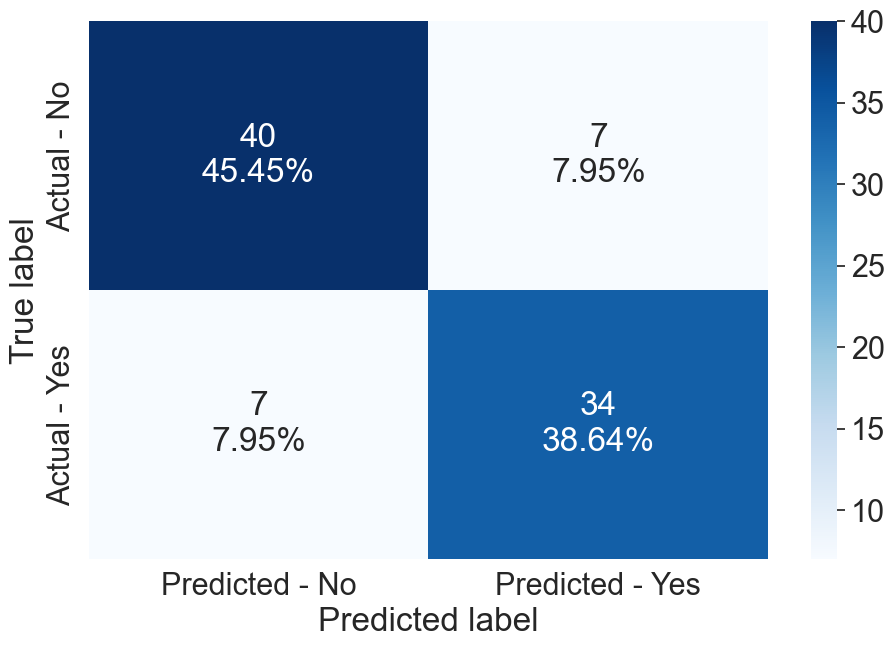

In [97]:
get_metrics_score(log_reg, X_train_scaled, y_train_clean, X_test_scaled, y_test_clean)
make_confusion_matrix(log_reg, X_test_scaled, y_test_clean)

## Support Vector Machines


 Performance: Support Vector Machine
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     0.86       0.85      
Precision    0.89       0.87      
Recall       0.78       0.80      
F1 Score     0.84       0.84      


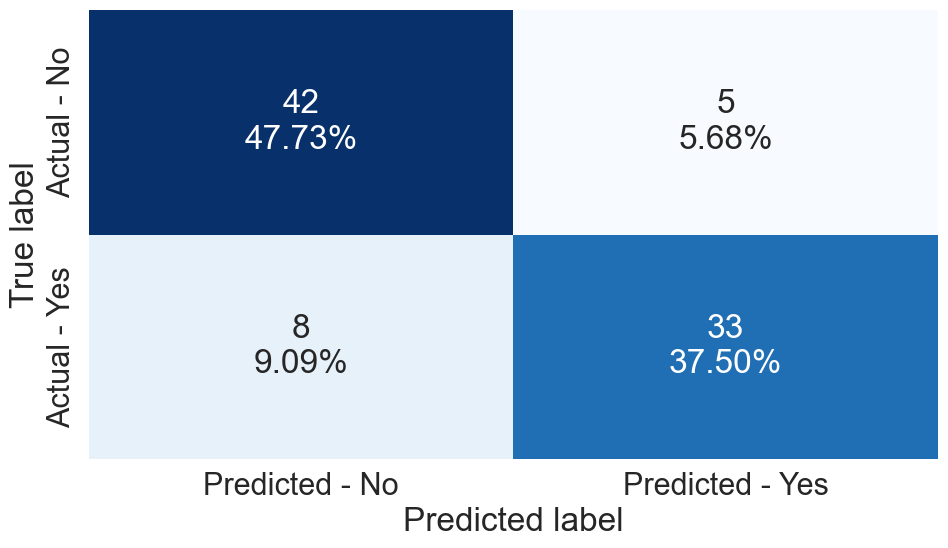

In [98]:
# Import additional required library
from sklearn.svm import SVC

# Build function to evaluate model on scaled data
def evaluate_model(name, model, X_train_scaled, y_train, X_test_scaled, y_test):
    print(f"\n Performance: {name}")
    print("-" * 50)

    # Predict on train and test sets
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)

    # Compute metrics
    train_metrics = {
        'Accuracy': accuracy_score(y_train, y_pred_train),
        'Precision': precision_score(y_train, y_pred_train),
        'Recall': recall_score(y_train, y_pred_train),
        'F1 Score': f1_score(y_train, y_pred_train)
    }

    test_metrics = {
        'Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision': precision_score(y_test, y_pred_test),
        'Recall': recall_score(y_test, y_pred_test),
        'F1 Score': f1_score(y_test, y_pred_test)
    }

    # Print table-style output
    print("{:<12} {:<10} {:<10}".format("Metric", "Train", "Test"))
    print("-" * 32)
    for metric in train_metrics:
        print("{:<12} {:<10.2f} {:<10.2f}".format(
            metric, train_metrics[metric], test_metrics[metric]
        ))

    # Confusion Matrix (Test Set Only)
    cm = confusion_matrix(y_test, y_pred_test)
    total = cm.sum()
    labels = [f"{v}\n{v/total:.2%}" for v in cm.flatten()]
    labels = np.array(labels).reshape(cm.shape)

    df_cm = pd.DataFrame(cm,
                         index=["Actual - No", "Actual - Yes"],
                         columns=["Predicted - No", "Predicted - Yes"])

    plt.figure(figsize=(10, 6))
    sns.heatmap(df_cm, annot=labels, fmt='', cmap='Blues', cbar=False)
    plt.title("")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

# 1. Create the SVM model with a linear kernel (or use 'rbf' for better non-linear results!)
svm_model = SVC(kernel='linear', probability=True, random_state=0)

# 2. Train the model using clean test and train sets
svm_model.fit(X_train_scaled, y_train_clean)

# 3. Call evaluative function using clean test and train sets
evaluate_model(
    "Support Vector Machine", 
    svm_model, 
    X_train_scaled, 
    y_train_clean,     # <-- Updated
    X_test_scaled, 
    y_test_clean       # <-- Updated
)

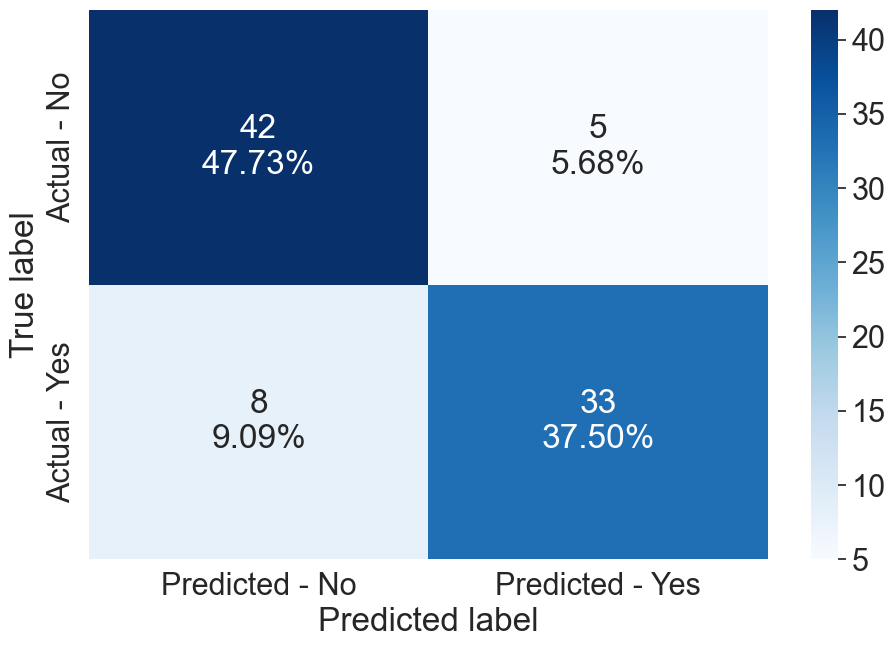

In [99]:
# Create SVM confusion matrix

def make_svm_confusion_matrix(model, X_test, y_test, labels=[0, 1]):
    # Predict using the model
    y_pred = model.predict(X_test)
    
    # Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    
    # Create labeled DataFrame
    df_cm = pd.DataFrame(
        cm,
        index=["Actual - No", "Actual - Yes"],
        columns=["Predicted - No", "Predicted - Yes"]
    )
    
    # Prepare annotation labels (counts + percentages)
    group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
    group_percentages = ["{0:.2%}".format(value) for value in cm.flatten() / np.sum(cm)]
    annot_labels = [f"{count}\n{percent}" for count, percent in zip(group_counts, group_percentages)]
    annot_labels = np.asarray(annot_labels).reshape(cm.shape)
    
    # Plot the heatmap
    plt.figure(figsize=(10, 7))
    sns.heatmap(df_cm, annot=annot_labels, fmt="", cmap="Blues")
    plt.title("")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.show()

make_svm_confusion_matrix(svm_model, X_test_scaled, y_test_clean)

## Boosting Algorithms

In [100]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    print(f"\n Performance: {name}")
    print("-" * 50)

    # Predict on train and test sets
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Compute metrics
    train_metrics = {
        'Accuracy': accuracy_score(y_train, y_pred_train),
        'Precision': precision_score(y_train, y_pred_train),
        'Recall': recall_score(y_train, y_pred_train),
        'F1 Score': f1_score(y_train, y_pred_train)
    }

    test_metrics = {
        'Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision': precision_score(y_test, y_pred_test),
        'Recall': recall_score(y_test, y_pred_test),
        'F1 Score': f1_score(y_test, y_pred_test)
    }

    # Print table-style output
    print("{:<12} {:<10} {:<10}".format("Metric", "Train", "Test"))
    print("-" * 32)
    for metric in train_metrics:
        print("{:<12} {:<10.2f} {:<10.2f}".format(
            metric, train_metrics[metric], test_metrics[metric]
        ))

    # Confusion Matrix (Test Set Only)
    cm = confusion_matrix(y_test, y_pred_test)
    total = cm.sum()
    labels = [f"{v}\n{v/total:.2%}" for v in cm.flatten()]
    labels = np.array(labels).reshape(cm.shape)

    df_cm = pd.DataFrame(cm,
                         index=["Actual - No", "Actual - Yes"],
                         columns=["Predicted - No", "Predicted - Yes"])

    plt.figure(figsize=(10, 6))
    sns.heatmap(df_cm, annot=labels, fmt='', cmap='Blues', cbar=False)
    plt.title("")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

## AdaBoost (Adaptive Boosting) - AdaBoost improves model performance by training weak learners sequentially and increasing the weight of misclassified samples after each round. It's one of the earliest and simplest boosting methods.


 Performance: AdaBoost
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     0.90       0.86      
Precision    0.90       0.85      
Recall       0.88       0.85      
F1 Score     0.89       0.85      


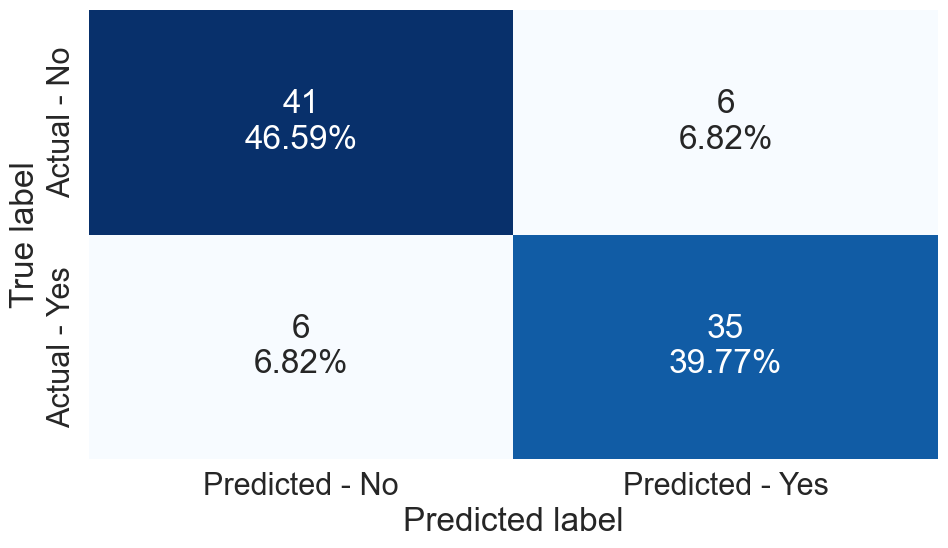

In [101]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(random_state=0)
adaboost.fit(X_train_clean, y_train_clean)

evaluate_model("AdaBoost", adaboost, X_train_clean, y_train_clean, X_test_clean, y_test_clean)

## Tuned AdaBoost


 Performance: Tuned AdaBoost
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     1.00       0.81      
Precision    1.00       0.80      
Recall       0.99       0.78      
F1 Score     0.99       0.79      


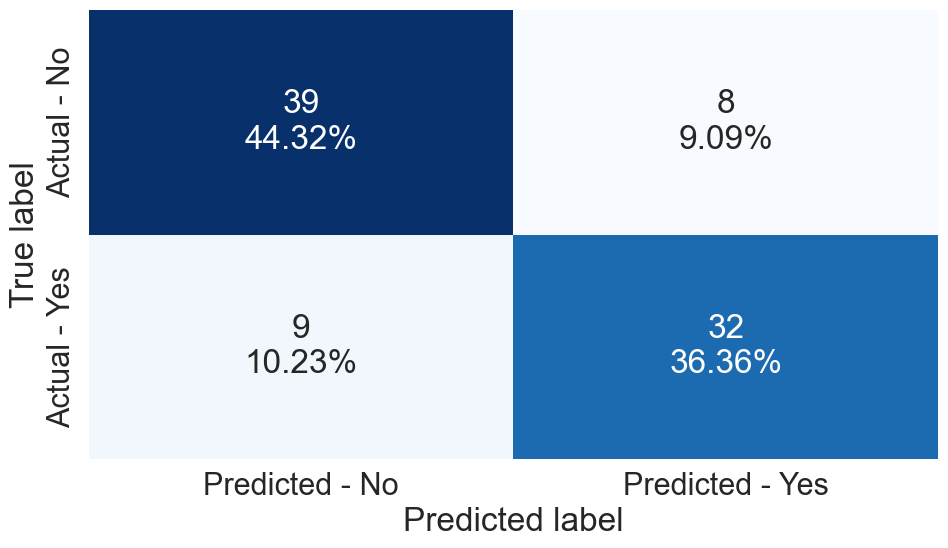

In [102]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

tuned_adaboost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=2),
    n_estimators=100,
    learning_rate=0.8,
    algorithm='SAMME',
    random_state=0
)

tuned_adaboost.fit(X_train_clean, y_train_clean)

# Evaluate the model
evaluate_model("Tuned AdaBoost", tuned_adaboost, X_train_clean, y_train_clean, X_test_clean, y_test_clean)

## Gradient Boosting - Gradient Boosting builds trees sequentially, but instead of reweighting like AdaBoost, it fits each new model to the residual errors of the previous one using a gradient descent approach. It often yields better accuracy than AdaBoost.


 Performance: Gradient Boosting
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     1.00       0.81      
Precision    1.00       0.80      
Recall       1.00       0.78      
F1 Score     1.00       0.79      


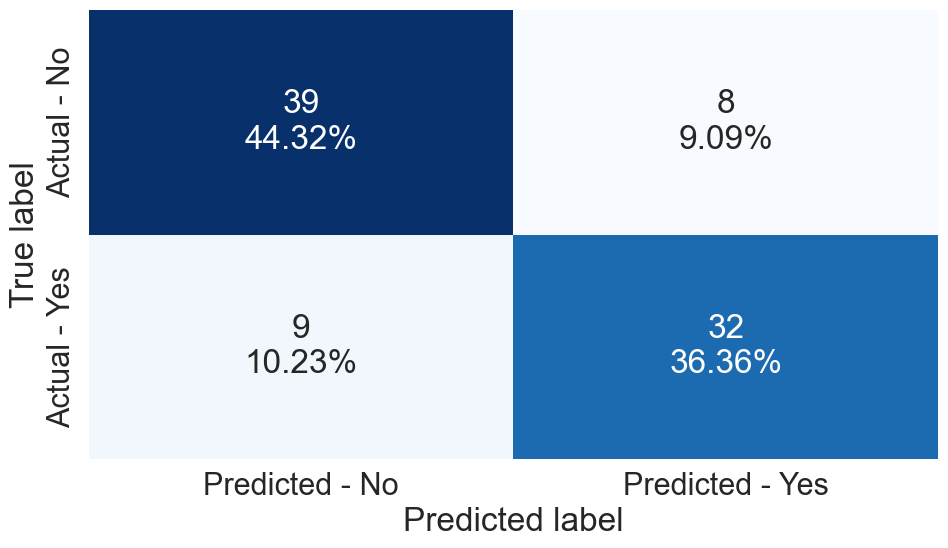

In [103]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=0)
gb.fit(X_train_clean, y_train_clean)
evaluate_model("Gradient Boosting", gb, X_train_clean, y_train_clean, X_test_clean, y_test_clean)

## Tuned Gradient Boosting


 Performance: Tuned Gradient Boosting
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     0.91       0.88      
Precision    0.91       0.89      
Recall       0.88       0.83      
F1 Score     0.89       0.86      


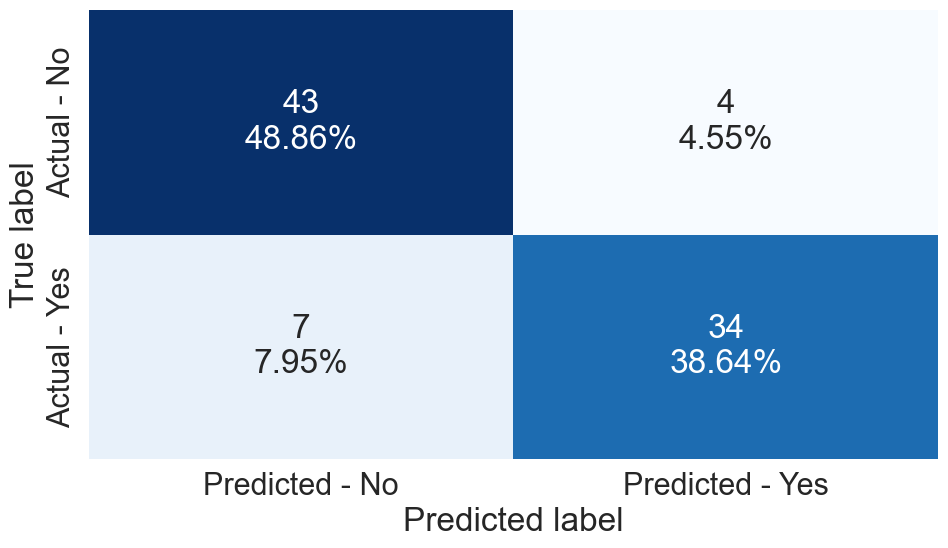

In [104]:

tuned_gb = GradientBoostingClassifier(
    n_estimators=150,      
    learning_rate=0.03,    
    max_depth=2,           
    subsample=0.7,         
    max_features=0.7,      
    random_state=0
)

tuned_gb.fit(X_train_clean, y_train_clean)
evaluate_model("Tuned Gradient Boosting", tuned_gb, X_train_clean, y_train_clean, X_test_clean, y_test_clean)

## XGBoost - XGBoost is a highly optimized implementation of gradient boosting with regularization, parallel computation, and missing value handling built in. It usually performs better and faster than Gradient Boosting.

In [105]:
%pip install xgboost

from xgboost import XGBClassifier

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.



 Performance: XGBoost (Default)
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     1.00       0.78      
Precision    1.00       0.75      
Recall       1.00       0.79      
F1 Score     1.00       0.77      


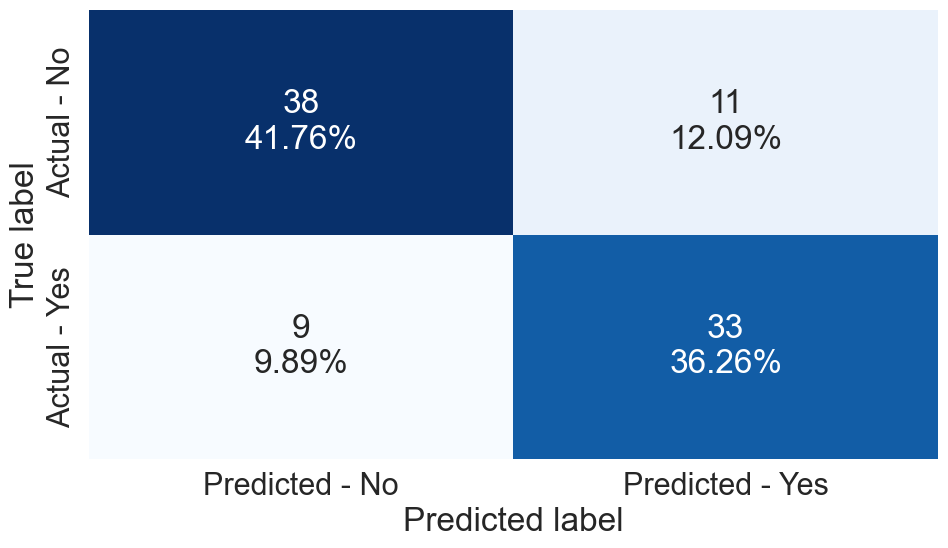

In [106]:
xgb = XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=0
)
xgb.fit(X_train, y_train)
evaluate_model("XGBoost (Default)", xgb, X_train, y_train, X_test, y_test)

## Tuned XGBoost


 Performance: Tuned XGBoost
--------------------------------------------------
Metric       Train      Test      
--------------------------------
Accuracy     0.86       0.86      
Precision    0.90       0.91      
Recall       0.78       0.78      
F1 Score     0.84       0.84      


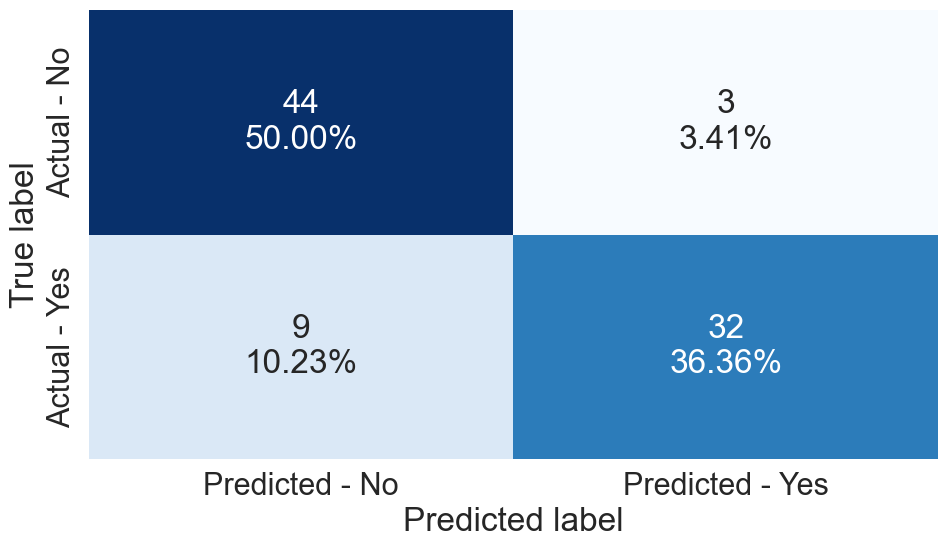

In [107]:
tuned_xgb = XGBClassifier(
    n_estimators=150,
    learning_rate=0.02,    
    max_depth=2,           
    subsample=0.7,         
    colsample_bytree=0.7,  
    reg_alpha=0.5,         
    reg_lambda=1.5,        
    random_state=0
)

tuned_xgb.fit(X_train_clean, y_train_clean)
evaluate_model("Tuned XGBoost", tuned_xgb, X_train_clean, y_train_clean, X_test_clean, y_test_clean)

### Creating Expanded Comparison Table Across all Models Ran

In [108]:
# Identify all models to compare
models = [
    dtree_base,
    dtree_tuned,
    bagging_base,
    bagging_tuned,
    rf_base,
    rf_tuned,
    log_reg,
    svm_model,
    adaboost,
    tuned_adaboost,
    gb,
    tuned_gb,
    xgb,
    tuned_xgb
]

In [109]:
# List of model names (must match order of models above)
model_names = [
    'Decision Tree',
    'Tuned Decision Tree',
    'Bagging Classifier',
    'Tuned Bagging Classifier',
    'Random Forest',
    'Tuned Random Forest',
    'Logistic Regression',
    'Support Vector Machine',
    'AdaBoost',
    'Tuned AdaBoost',
    'Gradient Boosting',
    'Tuned Gradient Boosting',
    'XGBoost',
    'Tuned XGBoost'
]

In [110]:
# Clear the lists
acc_train, acc_test = [], []
recall_train, recall_test = [], []
precision_train, precision_test = [], []
f1_train, f1_test = [], []
final_model_names = []

In [111]:
def get_metrics_score(model, X_train, y_train, X_test, y_test):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    recall_train = recall_score(y_train, y_pred_train)
    recall_test = recall_score(y_test, y_pred_test)

    precision_train = precision_score(y_train, y_pred_train)
    precision_test = precision_score(y_test, y_pred_test)

    f1_train = f1_score(y_train, y_pred_train)
    f1_test = f1_score(y_test, y_pred_test)

    return [
        acc_train, acc_test,
        recall_train, recall_test,
        precision_train, precision_test,
        f1_train, f1_test
    ]

In [112]:
model_data_map = {
    "Logistic Regression": (X_train_scaled, X_test_scaled, y_train_clean, y_test_clean),
    "Support Vector Machine": (X_train_scaled, X_test_scaled, y_train_clean, y_test_clean),
    "Tuned Random Forest": (X_train, X_test, y_train, y_test),  # Uses your original uncleaned data split!
    "AdaBoost": (X_train_clean, X_test_clean, y_train_clean, y_test_clean),
    "Tuned AdaBoost": (X_train_clean, X_test_clean, y_train_clean, y_test_clean),
    "Gradient Boosting": (X_train_clean, X_test_clean, y_train_clean, y_test_clean),
    "Tuned Gradient Boosting": (X_train_clean, X_test_clean, y_train_clean, y_test_clean),
    "XGBoost (Default)": (X_train_clean, X_test_clean, y_train_clean, y_test_clean),
    "XGBoost (Tuned)": (X_train_clean, X_test_clean, y_train_clean, y_test_clean)
}

In [113]:
for model, name in zip(models, model_names):
    if model is None:
        continue

    # Grab the exact X and y datasets needed for this specific model (clean or unclean depending on if the model is boosted or not)
    X_tr, X_te, y_tr, y_te = model_data_map.get(
        name, 
        (X_train_clean, X_test_clean, y_train_clean, y_test_clean)
    )

    # 2. Pass the matching variables cleanly into the scoring function
    scores = get_metrics_score(model, X_tr, y_tr, X_te, y_te)

    # 3. Append the metrics to the tracking lists
    acc_train.append(scores[0])
    acc_test.append(scores[1])
    recall_train.append(scores[2])
    recall_test.append(scores[3])
    precision_train.append(scores[4])
    precision_test.append(scores[5])
    f1_train.append(scores[6])
    f1_test.append(scores[7])
    final_model_names.append(name)

In [114]:
print("Lengths:", len(final_model_names), len(acc_train), len(acc_test), len(f1_test))

Lengths: 14 14 14 14


In [115]:
comparison_frame = pd.DataFrame({
    'Model': final_model_names,
    'Train_Accuracy': acc_train,
    'Test_Accuracy': acc_test,
    'Train_Recall': recall_train,
    'Test_Recall': recall_test,
    'Train_Precision': precision_train,
    'Test_Precision': precision_test,
    'Train_F1': f1_train,
    'Test_F1': f1_test
})

comparison_frame_sorted = comparison_frame.sort_values(by='Test_Recall', ascending=False) # Sort by most important metric

# Display the table
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
print(comparison_frame_sorted)

                       Model  Train_Accuracy  Test_Accuracy  Train_Recall  Test_Recall  Train_Precision  Test_Precision  Train_F1  Test_F1
5        Tuned Random Forest           0.943          0.835         0.969        0.857            0.913           0.800     0.940    0.828
8                   AdaBoost           0.900          0.864         0.876        0.854            0.904           0.854     0.890    0.854
6        Logistic Regression           0.848          0.841         0.784        0.829            0.874           0.829     0.826    0.829
11   Tuned Gradient Boosting           0.905          0.875         0.876        0.829            0.914           0.895     0.895    0.861
7     Support Vector Machine           0.858          0.852         0.784        0.805            0.894           0.868     0.835    0.835
3   Tuned Bagging Classifier           0.976          0.841         0.959        0.780            0.989           0.865     0.974    0.821
9             Tuned AdaBoos

## Final Model Performance Summary

### 1. Best Model: Tuned Random Forest
* **Peak Clinical Performance:** The Tuned Random Forest achieved the highest overall Test Recall of 85.7% along with an 83.5% Test Accuracy. 
* **Patient Safety Priority:** In a healthcare context, minimizing False Negatives is vital. Because this model prioritized Recall without severely sacrificing overall accuracy, it stands as the most reliable candidate.

### While Tuned Gradient Boosting offers the sharpest overall predictive accuracy, the Tuned Random Forest is selected as the final model due to its superior Test Recall (85.7%), maximizing patient safety by catching the highest percentage of true risk cases within this dataset.